# Meal Delivery Demand Forecasting with a Stacking Ensemble (Meal Delivery Dataset, Improved Method)

This notebook is a modified copy of `meal_delivery_methodology.ipynb`. It uses the same models (Random Forest, XGBoost, SVR, LSTM and two stacking ensembles) with the same settings, but prepares the data so that the models never see information from the test period. It also adds descriptive statistics and evaluation metrics, reduces the training time of the stacking ensembles and explains their forecasts. Changed lines in the code are marked `# CHANGED:`.

Before any modelling, Section 1 checks the data quality: missing values, duplicate records, invalid values, consistency between the prices, outliers, unusual weeks and how complete each meal's weekly records are. No problems that need fixing are found, so the data is used as it is.

The forecasts are one week ahead: each meal's orders for a week are predicted from its actual orders up to the week before (the lag inputs), the meal, and that week's prices and promotions (e-mail and homepage), which are assumed to be planned in advance. Forecasting further ahead would need lag inputs that end earlier.

Changes from `meal_delivery_methodology.ipynb`:
1. Descriptive statistics and histograms of the numeric variables are added (Section 3).
2. The data is split by week instead of at random: the first 80 % of weeks for training and the last 20 % for testing (Section 4).
3. Missing lag values are filled with training-set means after the split, instead of full-data means before it (Sections 2 and 4).
4. MSE, RMSE and SMAPE are added to the metrics (Section 5).
5. The LSTM is tested on the same rows as the other models and trains only on rows with a full 10-record history (Section 7).
6. The stacking meta-learner is tuned with `RidgeCV` instead of a grid search that retrains the whole stack (Sections 8 and 9).
7. A new section compares the training time and accuracy of both tuning methods (Section 11).
8. A new section explains the forecasts of both stacking ensembles with SHAP and LIME (Section 12).
9. A naive baseline (the previous record of the same meal) is added to the results as a reference point (Section 5).
10. Stacking 2's LSTM is retrained in every cross-validation fold instead of being trained once and reused (Section 9).
11. A paired significance test checks whether the stacking ensembles' errors differ from the best single model's (Section 10).

No input in this dataset contains the target, so no input is removed.

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading and data quality checks |
| 2 | Feature engineering: lagged orders |
| 3 | Data analysis and descriptive statistics |
| 4 | One-hot encoding, train/test split by week, imputation, scaling |
| 5 | Evaluation metrics |
| 6 | Random Forest, XGBoost and SVR with grid search |
| 7 | LSTM |
| 8 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 9 | Stacking 2: RF + XGBoost + SVR + LSTM → Ridge |
| 10 | Results and plots |
| 11 | Stacking training time vs accuracy |
| 12 | Explainability: SHAP and LIME |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. Move to the repository's main folder (the folder that holds datasets/), so the paths below
# work wherever the notebook is opened. On Google Colab, where the repository is not present yet, it is cloned first.
import os, sys
from pathlib import Path
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/meal_delivery_dataset.csv"

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets").is_dir()), None)
if root is not None:
    os.chdir(root)
elif "google.colab" in sys.modules:
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings and TensorFlow start-up logs
import time, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import GridSearchCV   # CHANGED: train_test_split removed because the split is now by date
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge, RidgeCV   # CHANGED: RidgeCV added for the stacking meta-learner
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score   # CHANGED: mean_squared_error added for MSE and RMSE
from xgboost import XGBRegressor

# TensorFlow / Keras for the LSTM
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
tf.get_logger().setLevel("ERROR")
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the tree models and the LSTM (CHANGED: no longer used for the split)
TEST_SIZE         = 0.20      # share of weeks held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SEQ_LEN           = 10        # LSTM input length: the 10 preceding records of the same meal
MONTH_RECORDS     = 4         # four weekly records (about one month) for the longest lag
LSTM_SCALE_TARGET = True      # LSTM learns a 0-1 scaled target; predictions are converted back to orders
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to orders
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # alpha values tested for the Ridge meta-learner
SHAP_ROWS         = 100       # CHANGED: new setting. Number of test rows explained with SHAP (chosen at random)
TARGET            = "num_orders"                        # column being forecast
CENTRE            = 13                                  # fulfilment centre used (the one with the most rows)
SERIES            = ["meal_id"]                         # one weekly series per meal
UNIT              = "orders"                            # unit of the target, for labels

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python, NumPy and TensorFlow random generators so results are repeatable
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seeds()

I0000 00:00:1794912266.841481   25629 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794912268.601697   25629 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Data loading and data quality
This loads the dataset, keeps one fulfilment centre and sorts it by week and meal, then checks its quality before any modelling.

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Rows in the file:", len(raw), "| Centres:", raw.center_id.nunique(), "| Meals:", raw.meal_id.nunique(), "| Weeks:", raw.week.nunique())
# Keep one fulfilment centre; its meals form one weekly series each
df = raw[raw.center_id == CENTRE].drop(columns=["id", "center_id"])
df["meal_id"] = df.meal_id.astype(str)                       # meal identifier is a category, not a number
# Lag features and LSTM windows rely on chronological order within each meal
df = df.sort_values(["week"] + SERIES).reset_index(drop=True)
print(f"Centre {CENTRE} rows:", len(df), "| Weeks:", df.week.min(), "to", df.week.max(), "| Meals (series):", df.groupby(SERIES).ngroups)
display(df.head())

Rows in the file: 456548 | Centres: 77 | Meals: 51 | Weeks: 145
Centre 13 rows: 7046 | Weeks: 1 to 145 | Meals (series): 51


,week,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1,1062,185.33,185.33,0,0,998
1,1,1109,231.86,299.73,1,0,3511
2,1,1198,169.78,168.78,0,0,688
3,1,1207,307.49,382.24,0,0,366
4,1,1216,454.93,456.93,0,0,13


### Data quality checks
The checks cover missing values, duplicate records, invalid values, consistency between columns, outliers (1.5 x IQR rule), unusual weeks and how complete each meal's weekly records are. Findings and how they are handled:
- No missing values, duplicates or invalid values, so no rows are removed or changed.
- The checkout price is slightly above the base price in about a quarter of the rows, almost always by less than 1.5 %. These are treated as normal price changes and kept.
- Orders are strongly right-skewed. The IQR rule flags many high values on the original scale but almost none on a log scale, so the high values are popular meals rather than errors, and they are kept.
- The unusually high weeks of a meal all have a promotion, so they are real responses to promotions and are kept. The unusually low weeks have no explanation in the data; with no evidence that they are errors, they are kept.
- In week 62 the whole centre (and the whole file) sold about half the usual orders. The data does not say why, so the week is kept; the lags of the following weeks are lower as a result.
- Some meals were introduced after week 1 and some weeks are missing inside a meal's period (the meal was not offered). These are left missing rather than filled with zero orders, and the lags use the previous week in which the meal appears.
- The order counts take only certain values (13, 14, 15, 26, 27, 28, 40, ...), which suggests the publisher transformed them. This cannot be reversed and does not affect the comparison between models.

In [4]:
NUMERIC_RAW = [TARGET, "checkout_price", "base_price"]

# Missing values and duplicates, in the whole file
print("Missing values (expect 0):", raw.isna().sum().sum(), "| Duplicate rows (expect 0):", raw.duplicated().sum(),
      "| Same week, centre and meal twice (expect 0):", raw.duplicated(["week", "center_id", "meal_id"]).sum())

# Invalid values and consistency between columns, in the centre used
print("Zero or negative orders or prices (expect 0):", int((df[NUMERIC_RAW] <= 0).sum().sum()),
      "| Promotion flags other than 0 or 1 (expect 0):", int((~df[["emailer_for_promotion", "homepage_featured"]].isin([0, 1])).sum().sum()))
ratio = df.checkout_price / df.base_price
print(f"Checkout / base price: {ratio.min():.2f} to {ratio.max():.2f} | above the base price: {(ratio > 1).sum()} rows,",
      f"of which more than 5 % above: {(ratio > 1.05).sum()}")

# Outliers by the 1.5 x IQR rule, for orders also on a log scale
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())
print("Outliers (1.5 x IQR):", {c: iqr_outliers(df[c]) for c in NUMERIC_RAW}, "| orders on a log scale:", iqr_outliers(np.log(df[TARGET])))
print(f"Skewness of orders: {df[TARGET].skew():.2f} (log scale: {np.log(df[TARGET]).skew():.2f})")

# Unusual weeks of a meal: orders far from that meal's usual level (robust z-score above 3.5 on a log scale)
log_orders = np.log(df[TARGET])
by_meal = log_orders.groupby(df.meal_id)
z = (log_orders - by_meal.transform("median")) / (1.4826 * by_meal.transform(lambda s: (s - s.median()).abs().median()))
promo = (df.emailer_for_promotion + df.homepage_featured) > 0
print(f"Unusually high weeks: {(z > 3.5).sum()} (share with a promotion: {promo[z > 3.5].mean():.0%}) | unusually low weeks: {(z < -3.5).sum()}")
total = df.groupby("week")[TARGET].sum()
print("Weeks where the centre's total orders fell below 60 % of the median week:", (total / total.median())[total / total.median() < 0.6].round(2).to_dict())

# Coverage: the weeks in which each meal is offered
span = df.groupby("meal_id").week.agg(["count", "min", "max"])
gaps = span["max"] - span["min"] + 1 - span["count"]
print(f"Meals offered in all {df.week.nunique()} weeks: {(span['count'] == df.week.nunique()).sum()} of {len(span)} |",
      f"introduced after week 1: {(span['min'] > 1).sum()} (fewest weeks: meal {span['count'].idxmin()}, {span['count'].min()} weeks) |",
      f"weeks missing inside a meal's period: {gaps.sum()} in {(gaps > 0).sum()} meals")

Missing values (expect 0): 0 | Duplicate rows (expect 0): 0 | Same week, centre and meal twice (expect 0): 0
Zero or negative orders or prices (expect 0): 0 | Promotion flags other than 0 or 1 (expect 0): 0
Checkout / base price: 0.22 to 1.22 | above the base price: 1741 rows, of which more than 5 % above: 37


Outliers (1.5 x IQR): {'num_orders': 512, 'checkout_price': 0, 'base_price': 0} | orders on a log scale: 1
Skewness of orders: 3.20 (log scale: -0.10)
Unusually high weeks: 53 (share with a promotion: 100%) | unusually low weeks: 90
Weeks where the centre's total orders fell below 60 % of the median week: {62: 0.5}
Meals offered in all 145 weeks: 27 of 51 | introduced after week 1: 6 (fewest weeks: meal 2104, 34 weeks) | weeks missing inside a meal's period: 50 in 19 meals


## 2. Feature engineering
This adds model inputs derived from past orders. Each meal is treated as its own weekly series, and the lags only use earlier records of the same meal:
* `Orders_last_week`: orders at the previous record of the meal.
* `Orders_last_two_weeks`: total orders over the previous 2 records.
* `Orders_last_four_weeks`: total orders over the previous 4 records (about one month).

A meal is not offered every week, so a "record" is the previous week in which that meal appears. The dataset has week numbers but no dates, so no calendar features (day of week, month) can be added.

The first records of each meal have no history for the lags. Those gaps are filled in Section 4, after the split, using training-set means.

In [5]:
# Lagged orders within each meal: shifting by one record first ensures a row's own orders never enter its lags
g = df.groupby(SERIES)[TARGET]
df["Orders_last_week"]       = g.shift(1)                                                    # previous record
df["Orders_last_two_weeks"]  = g.transform(lambda s: s.shift(1).rolling(2).sum())
df["Orders_last_four_weeks"] = g.transform(lambda s: s.shift(1).rolling(MONTH_RECORDS).sum())

# The first records of each meal have no history yet; they are filled in Section 4
LAG_COLS = ["Orders_last_week", "Orders_last_two_weeks", "Orders_last_four_weeks"]
print("Missing lag values (filled in Section 4):", df[LAG_COLS].isna().sum().to_dict())
# CHANGED: missing values are no longer filled here, because full-data means include test-period values
display(df.loc[df.groupby(SERIES).ngroup() == 0, ["week"] + SERIES + [TARGET] + LAG_COLS].head(8))   # first records of one meal

Missing lag values (filled in Section 4): {'Orders_last_week': 51, 'Orders_last_two_weeks': 102, 'Orders_last_four_weeks': 204}


,week,meal_id,num_orders,Orders_last_week,Orders_last_two_weeks,Orders_last_four_weeks
0,1,1062,998,NaN,NaN,NaN
45,2,1062,784,998.0,NaN,NaN
90,3,1062,1187,784.0,1782.0,NaN
135,4,1062,1079,1187.0,1971.0,NaN
180,5,1062,864,1079.0,2266.0,4048.0
224,6,1062,1336,864.0,1943.0,3914.0
269,7,1062,1229,1336.0,2200.0,4466.0
313,8,1062,1228,1229.0,2565.0,4508.0


## 3. Data analysis
This summarises the numeric variables with descriptive statistics and histograms, then plots how orders vary with the main inputs. The week-of-month test of the canteen notebook is not possible because the dataset has no dates.

### Descriptive statistics
Count, mean, standard deviation, range, skewness and kurtosis of each numeric variable, followed by their histograms. Skewness measures asymmetry (0 means symmetric) and kurtosis measures how heavy the tails are (0 is the same as a normal distribution). The missing counts are the lag values at the start of each meal's series.

,count,mean,std,min,25%,50%,75%,max,missing,skewness,kurtosis
num_orders,7046.0,609.785,731.416,13.00,148.00,337.00,810.75,10745.00,0,3.198,19.834
checkout_price,7046.0,334.936,152.516,94.09,212.43,297.82,445.23,728.53,0,0.694,-0.335
base_price,7046.0,355.689,159.238,94.12,241.53,310.43,457.90,728.53,0,0.635,-0.587
Orders_last_week,6995.0,610.157,732.068,13.00,148.00,338.00,811.00,10745.00,51,3.203,19.889
Orders_last_two_weeks,6944.0,1220.421,1376.853,26.00,300.00,690.00,1635.00,16792.00,102,2.480,10.280
Orders_last_four_weeks,6842.0,2443.427,2612.695,81.00,646.00,1418.00,3266.50,24757.00,204,1.991,5.077


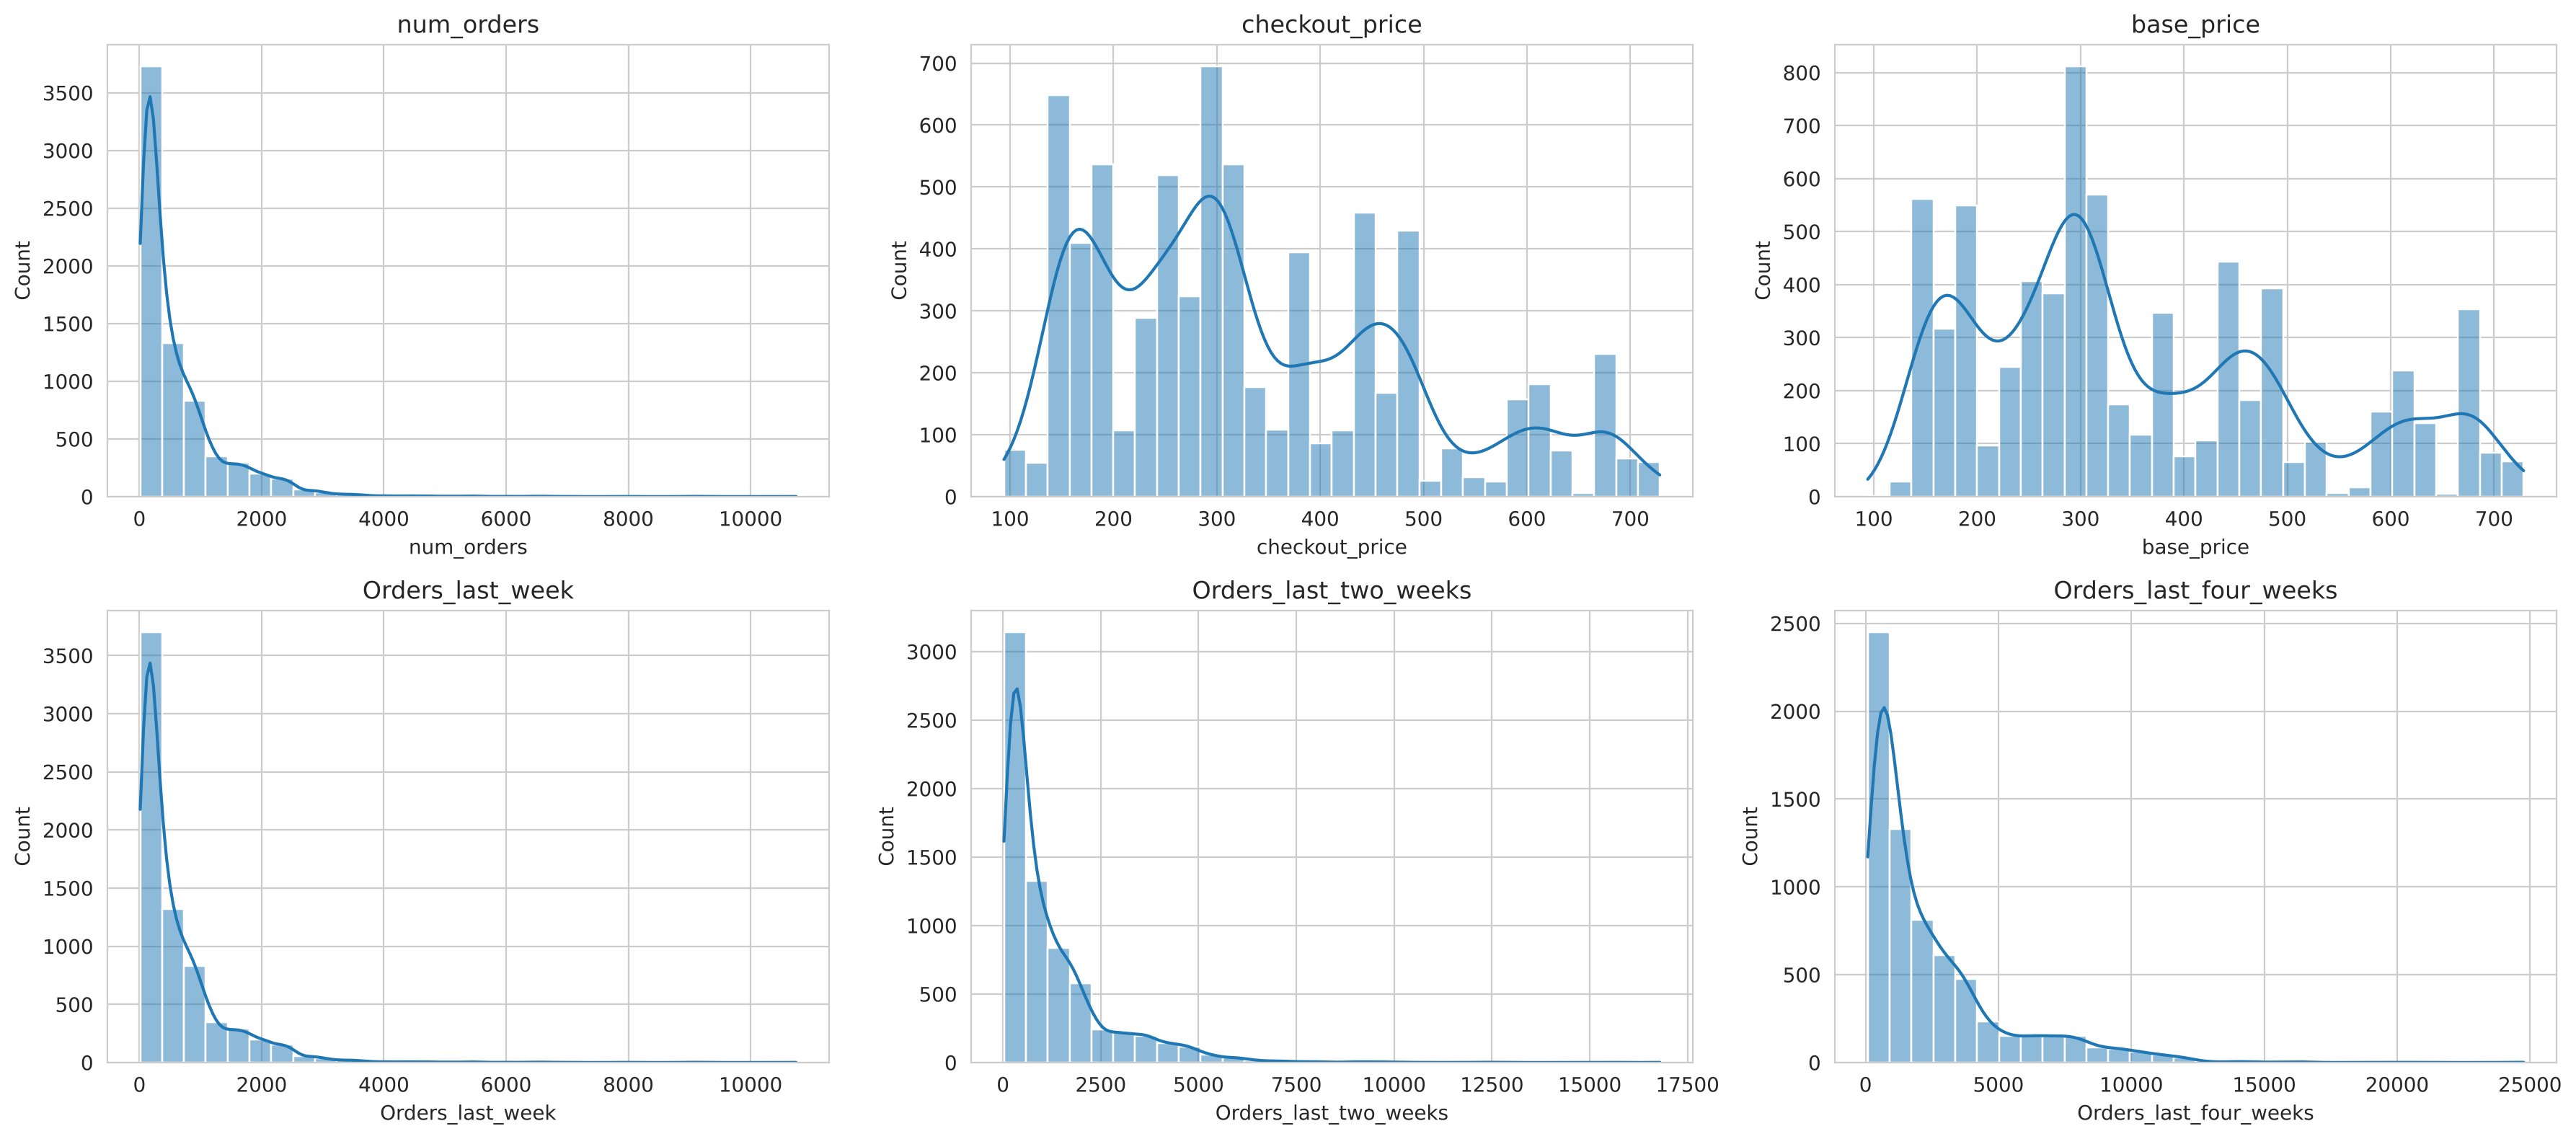

In [6]:
# CHANGED: new cell for descriptive statistics and histograms of the numeric variables
NUMERIC = [TARGET, "checkout_price", "base_price"] + LAG_COLS
desc = df[NUMERIC].describe().T                      # count, mean, std, min, quartiles, max
desc["missing"]  = df[NUMERIC].isna().sum()
desc["skewness"] = df[NUMERIC].skew()
desc["kurtosis"] = df[NUMERIC].kurt()                # excess kurtosis, 0 for a normal distribution
display(desc.round(3))

# Histogram of each numeric variable
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=a).set_title(col)
plt.tight_layout(); plt.show()

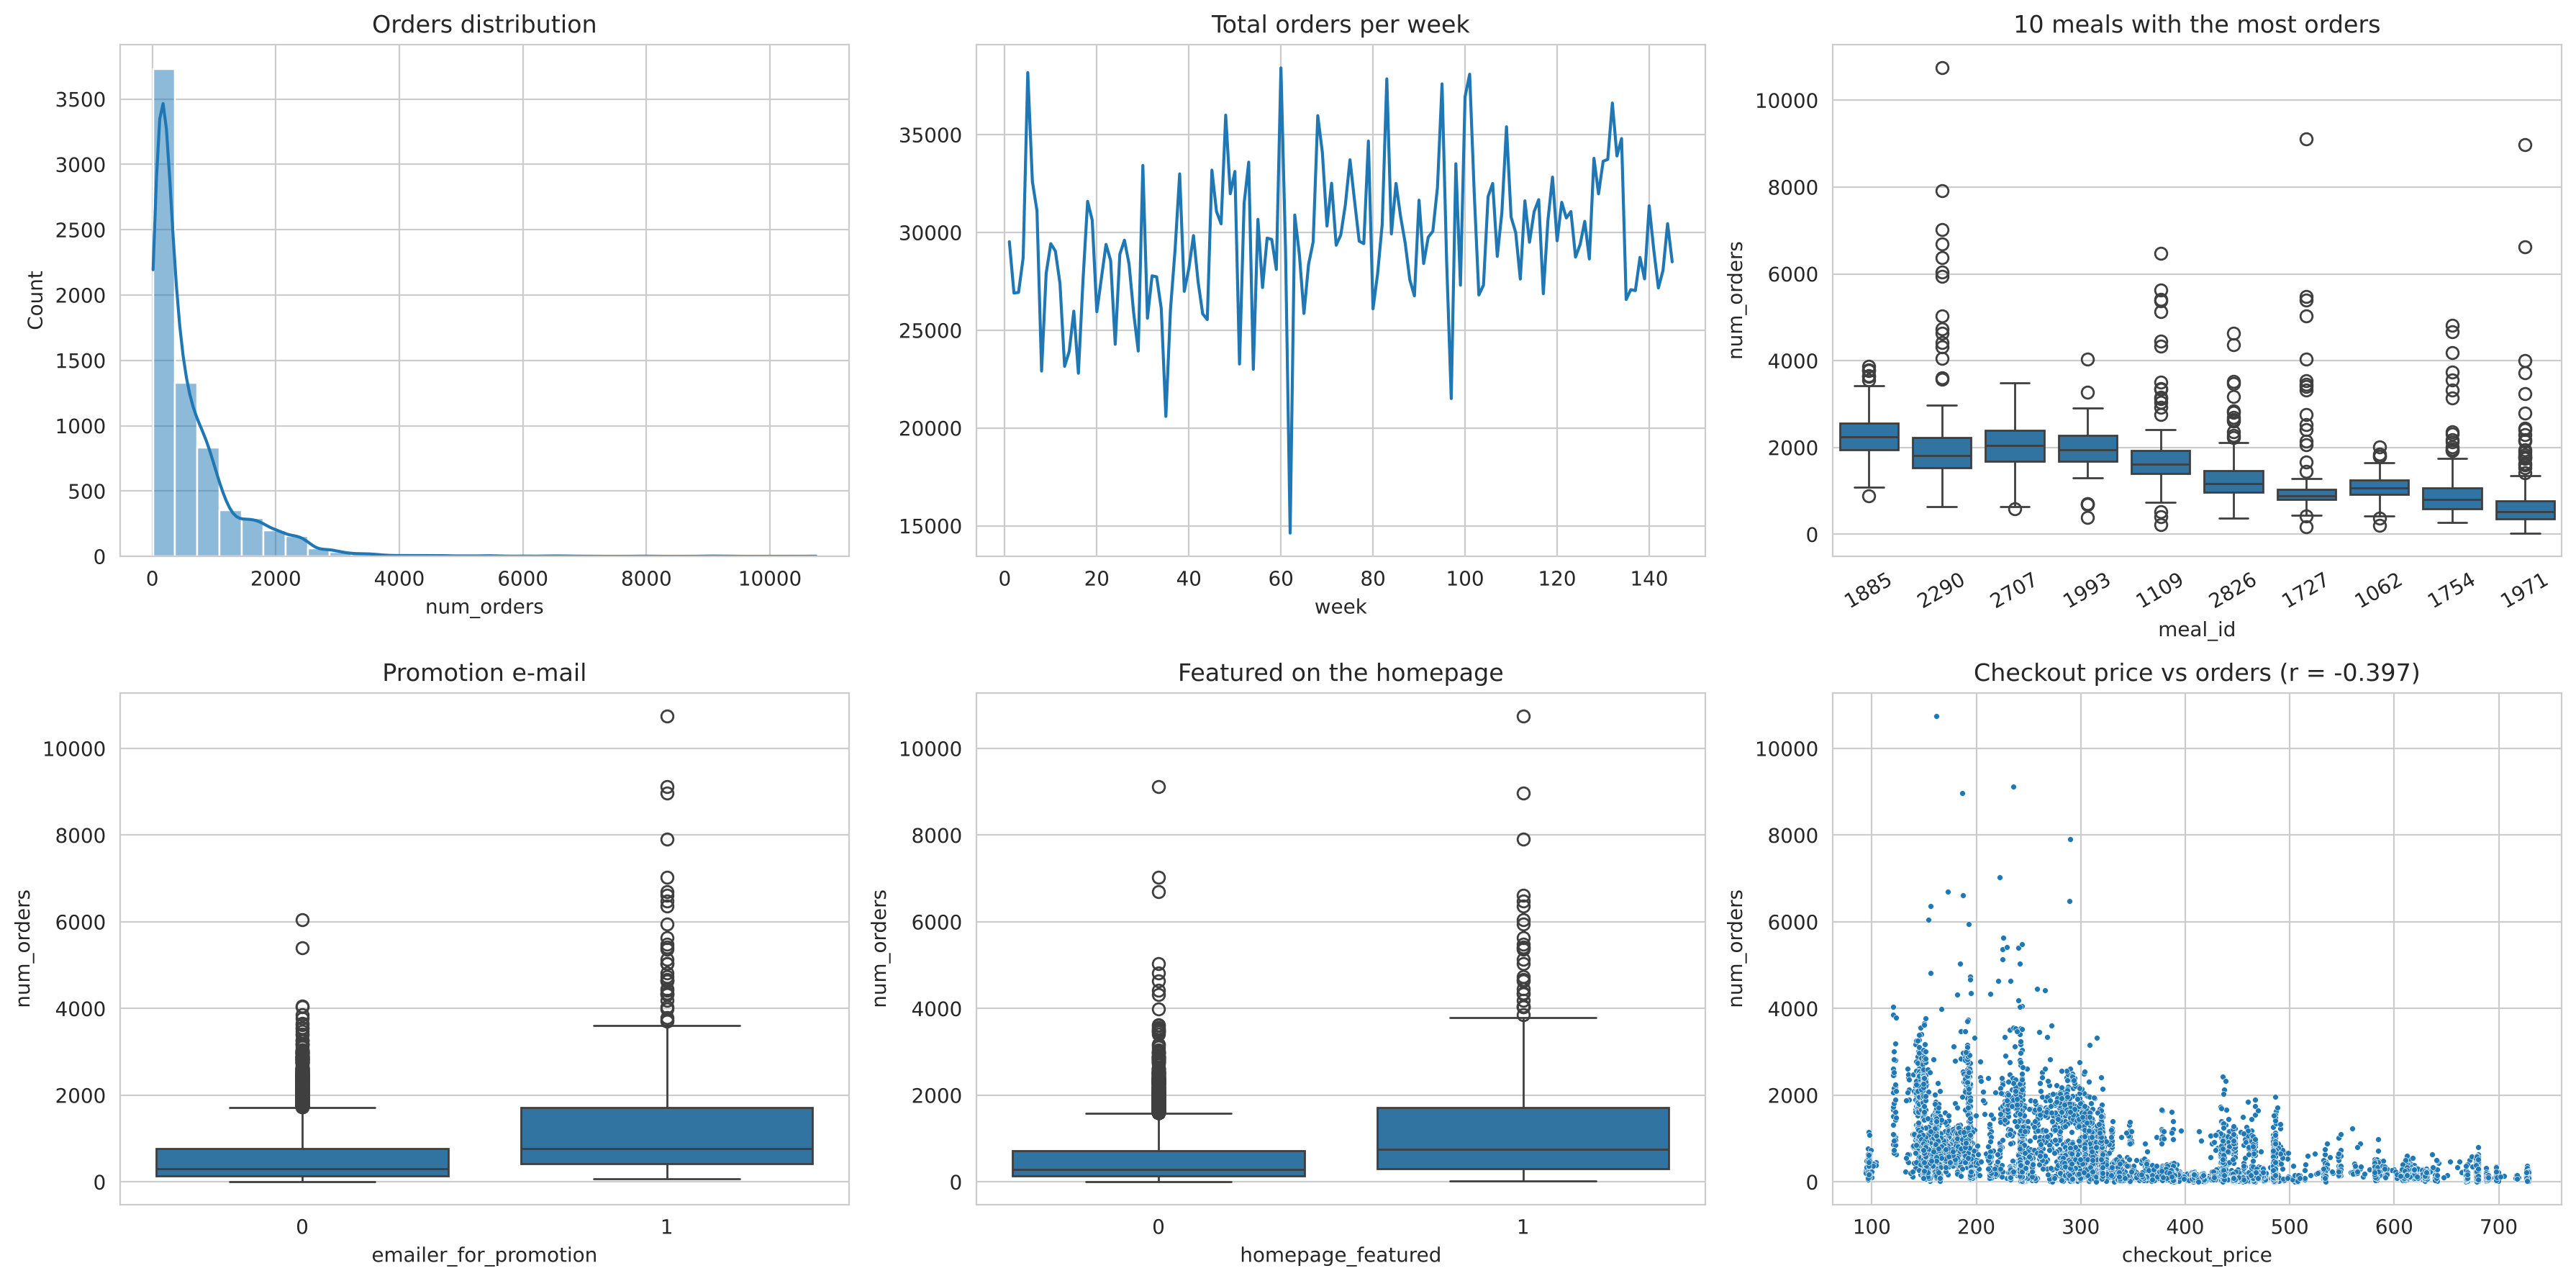

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of weekly orders per meal
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Orders distribution")
# Total orders of the centre in each week
ax[0, 1].plot(df.groupby("week")[TARGET].sum()); ax[0, 1].set(title="Total orders per week", xlabel="week")
# Orders of the 10 meals with the most orders
top = df.groupby("meal_id")[TARGET].sum().nlargest(10).index
sns.boxplot(data=df[df.meal_id.isin(top)], x="meal_id", y=TARGET, order=top, ax=ax[0, 2]).set_title("10 meals with the most orders")
ax[0, 2].tick_params(axis="x", rotation=30)
# Orders with and without each promotion
sns.boxplot(data=df, x="emailer_for_promotion", y=TARGET, ax=ax[1, 0]).set_title("Promotion e-mail")
sns.boxplot(data=df, x="homepage_featured", y=TARGET, ax=ax[1, 1]).set_title("Featured on the homepage")
# Checkout price against orders, with their correlation in the title
sns.scatterplot(data=df, x="checkout_price", y=TARGET, s=8, ax=ax[1, 2]).set_title(
    f"Checkout price vs orders (r = {df[['checkout_price', TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

## 4. Encoding, split, imputation and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Rows are split by week: the first 80 % of weeks form the training set and the last 20 % the test set, so every model is trained on earlier weeks and tested on later ones. The split is made on row numbers so the LSTM windows use the same training and test rows.
3. Missing lag values are filled with the training-set mean of each lag column.
4. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in orders.

In [8]:
CAT_COLS = ["meal_id"]
NUM_COLS = ["checkout_price", "base_price", "emailer_for_promotion", "homepage_featured"] + LAG_COLS

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# CHANGED: split by week instead of at random, so no training row comes after a test row
weeks  = np.sort(df.week.unique())
cutoff = weeks[-int(np.ceil(len(weeks) * TEST_SIZE))]          # first test week: the last 20 % of weeks are the test period
idx_tr, idx_te = np.where(df.week < cutoff)[0], np.where(df.week >= cutoff)[0]
print("Train: weeks", df.week.iloc[idx_tr[0]], "to", df.week.iloc[idx_tr[-1]], f"({len(idx_tr)} rows)",
      "| Test: weeks", df.week.iloc[idx_te[0]], "to", df.week.iloc[idx_te[-1]], f"({len(idx_te)} rows)")

# CHANGED: missing lag values filled with training-set means (previously full-data means before the split)
X = X.fillna(X.iloc[idx_tr].mean())

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

Train: weeks 1 to 116 (5568 rows) | Test: weeks 117 to 145 (1478 rows)
58 inputs | train (5568, 58) | test (1478, 58)
['checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'Orders_last_week', 'Orders_last_two_weeks', 'Orders_last_four_weeks', 'meal_id_1062', 'meal_id_1109', 'meal_id_1198', 'meal_id_1207', 'meal_id_1216', 'meal_id_1230', 'meal_id_1247', 'meal_id_1248', 'meal_id_1311', 'meal_id_1438', 'meal_id_1445', 'meal_id_1525', 'meal_id_1543', 'meal_id_1558', 'meal_id_1571', 'meal_id_1727', 'meal_id_1754', 'meal_id_1770', 'meal_id_1778', 'meal_id_1803', 'meal_id_1847', 'meal_id_1878', 'meal_id_1885', 'meal_id_1902', 'meal_id_1962', 'meal_id_1971', 'meal_id_1993', 'meal_id_2104', 'meal_id_2126', 'meal_id_2139', 'meal_id_2290', 'meal_id_2304', 'meal_id_2306', 'meal_id_2322', 'meal_id_2444', 'meal_id_2490', 'meal_id_2492', 'meal_id_2494', 'meal_id_2539', 'meal_id_2569', 'meal_id_2577', 'meal_id_2581', 'meal_id_2631', 'meal_id_2640', 'meal_id_2664', 'meal_id_270

## 5. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MSE=\frac1n\sum(y-\hat y)^2$ · $RMSE=\sqrt{MSE}$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $SMAPE=\frac{100}{n}\sum\frac{2|y-\hat y|}{|y|+|\hat y|}$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 10.

In [9]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in orders / %), R2, training time and test-set size
    mape  = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    smape = np.mean(2 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100   # CHANGED: SMAPE added
    mse   = mean_squared_error(y_true, y_pred)                                                # CHANGED: MSE added
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse),                                                               # CHANGED: RMSE added
            "MAPE (%)": mape, "SMAPE (%)": smape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

### Baseline
A naive forecast is the reference point for every model: each test row is forecast with the orders at the previous record of the same meal (the training mean for a meal's first record). A model is only useful if it does clearly better than this.

In [10]:
# CHANGED: new cell. Naive baseline: each test row gets the orders at the previous record of its meal
t0 = time.time()
prev = df.groupby(SERIES)[TARGET].shift(1).to_numpy()[idx_te]
preds["Naive"], truth["Naive"] = np.where(np.isnan(prev), y_tr.mean(), prev), y_te
results.append(evaluate("Naive (previous record of the meal)", y_te, preds["Naive"], time.time() - t0))

## 6. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to orders.

In [11]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to orders
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}  (60.7s)


XGBoost  {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}  (7.3s)


SVR      {'regressor__C': 1, 'regressor__epsilon': 0.1}  (21.1s)


## 7. LSTM
Each sample is a window of the **10 preceding records of the same meal** (all scaled inputs), and the label is the orders at the following record. The windows use the same training and test rows as the other models. Training rows with fewer than 10 earlier records of their meal are left out of the LSTM's training set. The test windows are passed as validation data, which only reports a score during training and does not change the model.

In [12]:
def build_lstm(n_features):
    # Two stacked LSTM layers (50 units each) with 20 % dropout after each, then one output neuron
    model = Sequential([Input(shape=(SEQ_LEN, n_features)),
                        LSTM(50, return_sequences=True), Dropout(0.2),
                        LSTM(50, return_sequences=False), Dropout(0.2),
                        Dense(1)])
    model.compile(optimizer="adam", loss="mse")           # Adam with its default learning rate, mean squared error loss
    return model

class LSTMRegressor:
    # Wraps the Keras LSTM with optional 0-1 target scaling; predictions always come back in orders.
    def __init__(self, n_features, scale_target=LSTM_SCALE_TARGET):
        self.n_features, self.scale_target = n_features, scale_target
    def fit(self, W, y, validation_data=None):
        set_seeds()                                        # every LSTM starts from the same random state
        self.ys = MinMaxScaler().fit(y.reshape(-1, 1)) if self.scale_target else None
        f = (lambda v: self.ys.transform(v.reshape(-1, 1)).ravel()) if self.scale_target else (lambda v: v)
        val = None if validation_data is None else (validation_data[0], f(validation_data[1]))
        self.model = build_lstm(self.n_features)
        self.model.fit(W, f(y), epochs=20, batch_size=32, validation_data=val, verbose=0)
        return self
    def predict(self, W):
        p = self.model.predict(W, verbose=0)
        return (self.ys.inverse_transform(p) if self.scale_target else p).ravel()

# Row numbers of the 10 previous records of each row's series. Records before a series' first record are
# padded by repeating that first record (only Stacking 2 needs that, because it must predict every row).
PREV = np.zeros((len(df), SEQ_LEN), dtype=int)
for rows in df.groupby(SERIES).indices.values():          # row numbers of one series, in time order
    for k, r in enumerate(rows):
        PREV[r] = rows[np.clip(np.arange(k - SEQ_LEN, k), 0, None)]
HISTORY = df.groupby(SERIES).cumcount().to_numpy()         # number of earlier records in the same series

def make_windows(days):
    # Window for row t = the 10 previous records of its series
    return np.stack([X_all[PREV[t]] for t in days])

# CHANGED: windows are built from the week split, so the LSTM is tested on the same rows as the other models.
# Previously the complete windows were split separately at random, giving a different test set.
# Only training rows with 10 earlier records of their meal are used, so no padded windows are needed.
lstm_tr = idx_tr[HISTORY[idx_tr] >= SEQ_LEN]
W_tr, W_te = make_windows(lstm_tr), make_windows(idx_te)
yw_tr, yw_te = y[lstm_tr], y_te

# Train (timed), predict the test windows and record the metrics
t0 = time.time()
lstm = LSTMRegressor(W_tr.shape[2]).fit(W_tr, yw_tr, validation_data=(W_te, yw_te))   # CHANGED: number of features taken from W_tr
secs = time.time() - t0
preds["LSTM"], truth["LSTM"] = lstm.predict(W_te), yw_te
results.append(evaluate("LSTM", yw_te, preds["LSTM"], secs))
print(f"LSTM trained in {secs:.1f}s")

LSTM trained in 38.2s


## 8. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by `RidgeCV` from the same candidate values, using MAE and leave-one-out cross-validation on the out-of-fold predictions. Since `alpha` only affects the Ridge step, the base models do not need to be retrained to compare `alpha` values, so each base model is trained 6 times (5 folds and a final fit) instead of once for every `alpha` value and fold. Section 11 measures the time saved.

In [13]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions.
# CHANGED: alpha is chosen by RidgeCV inside the stack instead of by a GridSearchCV around the whole stack.
# Alpha only affects the Ridge step, but the grid search retrained every base model for each of the
# 5 alpha values and 5 folds. RidgeCV tests the same alpha values with MAE on the out-of-fold predictions
# the stack already has, so the base models are only trained once. The model and settings are the same.
s1 = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                       final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
                       cv=CV_FOLDS, passthrough=False, n_jobs=-1).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: alpha = {s1.final_estimator_.alpha_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.final_estimator_.coef_, 3)} ({secs:.1f}s)")   # CHANGED: alpha read from RidgeCV

Stacking 1: alpha = 100.0 | Ridge weights [RF, XGB, SVR] = [0.273 0.64  0.146] (14.7s)


## 9. Stacking 2: RF + XGBoost + SVR + LSTM → Ridge
This uses the same stacking procedure as Stacking 1 (including `RidgeCV` for the meta-learner), with the LSTM added as a fourth base model.
* Each row's input is `[row features | flattened 10-record window]`. Column selectors give RF, XGBoost and SVR the row features only, and the LSTM the window only.
* With `STACK2_LSTM_MODE = "refit"`, a new LSTM is trained in every cross-validation fold, so the predictions Ridge learns from always come from an LSTM that has not seen those rows. With `RidgeCV` this takes 6 LSTM trainings (5 folds and a final fit), all included in the training time.
* `"prefit"` trains the LSTM once on all training rows and reuses it inside every fold. It is faster, but Ridge then learns from LSTM predictions on rows the LSTM was trained on. In that mode, the cell after the model compares the LSTM's accuracy on those rows with its accuracy on unseen test rows.

In [14]:
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.pipeline import Pipeline
from joblib import parallel_backend

STACK2_LSTM_MODE = "refit"    # CHANGED: was "prefit". "refit" = new LSTM trained in every fold, so Ridge never learns from
                              # LSTM predictions on rows the LSTM was trained on; "prefit" = LSTM trained once and reused in every fold
PREFIT_LSTM = {}              # the once-trained LSTM, looked up by key so sklearn's clone() never copies a Keras model

class ColumnSlice(TransformerMixin, BaseEstimator):
    # Keeps columns [start, stop) of the combined input.
    def __init__(self, start=0, stop=None):
        self.start, self.stop = start, stop
    def fit(self, Z, y=None):
        return self
    def transform(self, Z):
        return Z[:, self.start:self.stop]

class WindowLSTM(RegressorMixin, BaseEstimator):
    # LSTM base model for StackingRegressor; input = flattened 10-record windows.
    # With prefit_key, fit() only attaches the once-trained model; otherwise it trains a new LSTM.
    def __init__(self, n_features=1, prefit_key=None):
        self.n_features, self.prefit_key = n_features, prefit_key
    def _windows(self, Z):
        return Z.reshape(-1, SEQ_LEN, self.n_features)      # flat rows back to (samples, 10 records, features)
    def fit(self, Z, y):
        self.model_ = (PREFIT_LSTM[self.prefit_key] if self.prefit_key
                       else LSTMRegressor(self.n_features).fit(self._windows(Z), y))
        return self
    def predict(self, Z):
        return self.model_.predict(self._windows(Z))

# Combined input: the row's own features followed by its flattened 10-record window
p     = X_all.shape[1]
W_all = make_windows(np.arange(len(y)))                       # every row gets a window (first 10 padded)
Z_all = np.hstack([X_all, W_all.reshape(len(y), -1)])         # [row features | flattened window]
Z_tr, Z_te = Z_all[idx_tr], Z_all[idx_te]
on_day = lambda est: Pipeline([("day_features", ColumnSlice(0, p)), ("model", clone(est))])   # base model on row features only

t0 = time.time()
if STACK2_LSTM_MODE == "prefit":
    PREFIT_LSTM["stack2"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)      # the single LSTM training
# LSTM base model on the window columns only
lstm_base = Pipeline([("window", ColumnSlice(p, None)),
                      ("model", WindowLSTM(p, "stack2" if STACK2_LSTM_MODE == "prefit" else None))])

# Same stacking set-up as Stacking 1, with the LSTM as a fourth base model.
# CHANGED: RidgeCV meta-learner instead of a GridSearchCV around the whole stack (see Section 8)
s2 = StackingRegressor(
    estimators=[("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_base)],
    final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
    cv=CV_FOLDS, passthrough=False, n_jobs=-1)                               # base models fitted in parallel
# Threads instead of separate processes, so every worker shares the one in-memory Keras model
with parallel_backend("threading"):
    s2.fit(Z_tr, y_tr)
secs = time.time() - t0
preds["Stacking 2"], truth["Stacking 2"] = s2.predict(Z_te), y_te
results.append(evaluate("Stacking 2 (RF, XGBoost, SVR, LSTM)", y_te, preds["Stacking 2"], secs))
print(f"Stacking 2 ({STACK2_LSTM_MODE}): alpha = {s2.final_estimator_.alpha_} | Ridge weights [RF, XGB, SVR, LSTM] = "
      f"{np.round(s2.final_estimator_.coef_, 3)} ({secs:.1f}s)")                    # CHANGED: alpha read from RidgeCV

Stacking 2 (refit): alpha = 100.0 | Ridge weights [RF, XGB, SVR, LSTM] = [ 0.274  0.636  0.202 -0.052] (148.0s)


In [15]:
# Prefit LSTM accuracy on the training rows it was trained on (whose predictions train Ridge) vs unseen test rows
if STACK2_LSTM_MODE == "prefit":
    m = PREFIT_LSTM["stack2"]
    tr_hat, te_hat = m.predict(W_all[idx_tr]), m.predict(W_all[idx_te])
    display(pd.DataFrame({f"MAE ({UNIT})": [mean_absolute_error(y_tr, tr_hat), mean_absolute_error(y_te, te_hat)],
                          "R2": [r2_score(y_tr, tr_hat), r2_score(y_te, te_hat)]},
                         index=["Training rows (seen, fed to Ridge)", "Test rows (unseen)"]).round(3))

## 10. Results
These are the test-set metrics for the baseline and all six models, all evaluated on the same test rows (the last 20 % of weeks).

In [16]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MSE,RMSE,MAPE (%),SMAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,,,,
Naive (previous record of the meal),196.284,263708.449,513.526,51.008,37.401,48.992,0.557,0.002,1478
RF,146.530,110433.291,332.315,41.602,29.799,58.398,0.815,60.691,1478
XGBoost,145.525,110314.888,332.137,41.233,29.738,58.767,0.815,7.257,1478
SVR,166.539,179282.593,423.418,41.658,31.201,58.342,0.699,21.117,1478
LSTM,209.365,217559.154,466.432,76.896,43.327,23.104,0.635,38.152,1478
"Stacking 1 (RF, XGBoost, SVR)",141.738,106916.470,326.981,37.437,29.781,62.563,0.821,14.715,1478
"Stacking 2 (RF, XGBoost, SVR, LSTM)",142.199,106431.403,326.238,37.370,29.991,62.630,0.821,147.986,1478


### Significance of the differences
Each stacking ensemble is compared with the best single model (lowest MAE), and the two ensembles with each other. Both models in a comparison predict the same test rows, so their absolute errors are paired row by row. A Wilcoxon signed-rank test checks whether one model's errors are consistently smaller than the other's; a p-value below 0.05 means the difference is unlikely to be due to chance. Errors in neighbouring weeks are related, so the p-values are approximate.

In [17]:
# CHANGED: new cell. Paired Wilcoxon signed-rank test on the absolute errors of each model on the same test rows
from scipy.stats import wilcoxon

single = [m for m in ["RF", "XGBoost", "SVR", "LSTM"] if m in preds]
best_single = min(single, key=lambda m: mean_absolute_error(truth[m], preds[m]))   # single model with the lowest MAE
abs_err = lambda m: np.abs(np.ravel(truth[m]) - np.ravel(preds[m]))                 # absolute error of a model on every test row

tests = []
for m1, m2 in [("Stacking 1", best_single), ("Stacking 2", best_single), ("Stacking 2", "Stacking 1")]:
    if m1 not in preds or m2 not in preds:
        continue
    assert np.array_equal(np.ravel(truth[m1]), np.ravel(truth[m2]))                 # both models predict the same rows
    e1, e2 = abs_err(m1), abs_err(m2)
    p_value = wilcoxon(e1, e2).pvalue
    tests.append({"Comparison": f"{m1} vs {m2}", "MAE difference": e1.mean() - e2.mean(),
                  "Rows where the first model is better (%)": np.mean(e1 < e2) * 100,
                  "p-value": p_value, "Significant at 5 %": "yes" if p_value < 0.05 else "no"})
display(pd.DataFrame(tests).set_index("Comparison").round(4))

,MAE difference,Rows where the first model is better (%),p-value,Significant at 5 %
Comparison,,,,
Stacking 1 vs XGBoost,-3.7863,52.9770,0.0003,yes
Stacking 2 vs XGBoost,-3.3252,51.7591,0.0091,yes
Stacking 2 vs Stacking 1,0.4610,46.8200,0.0074,yes


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

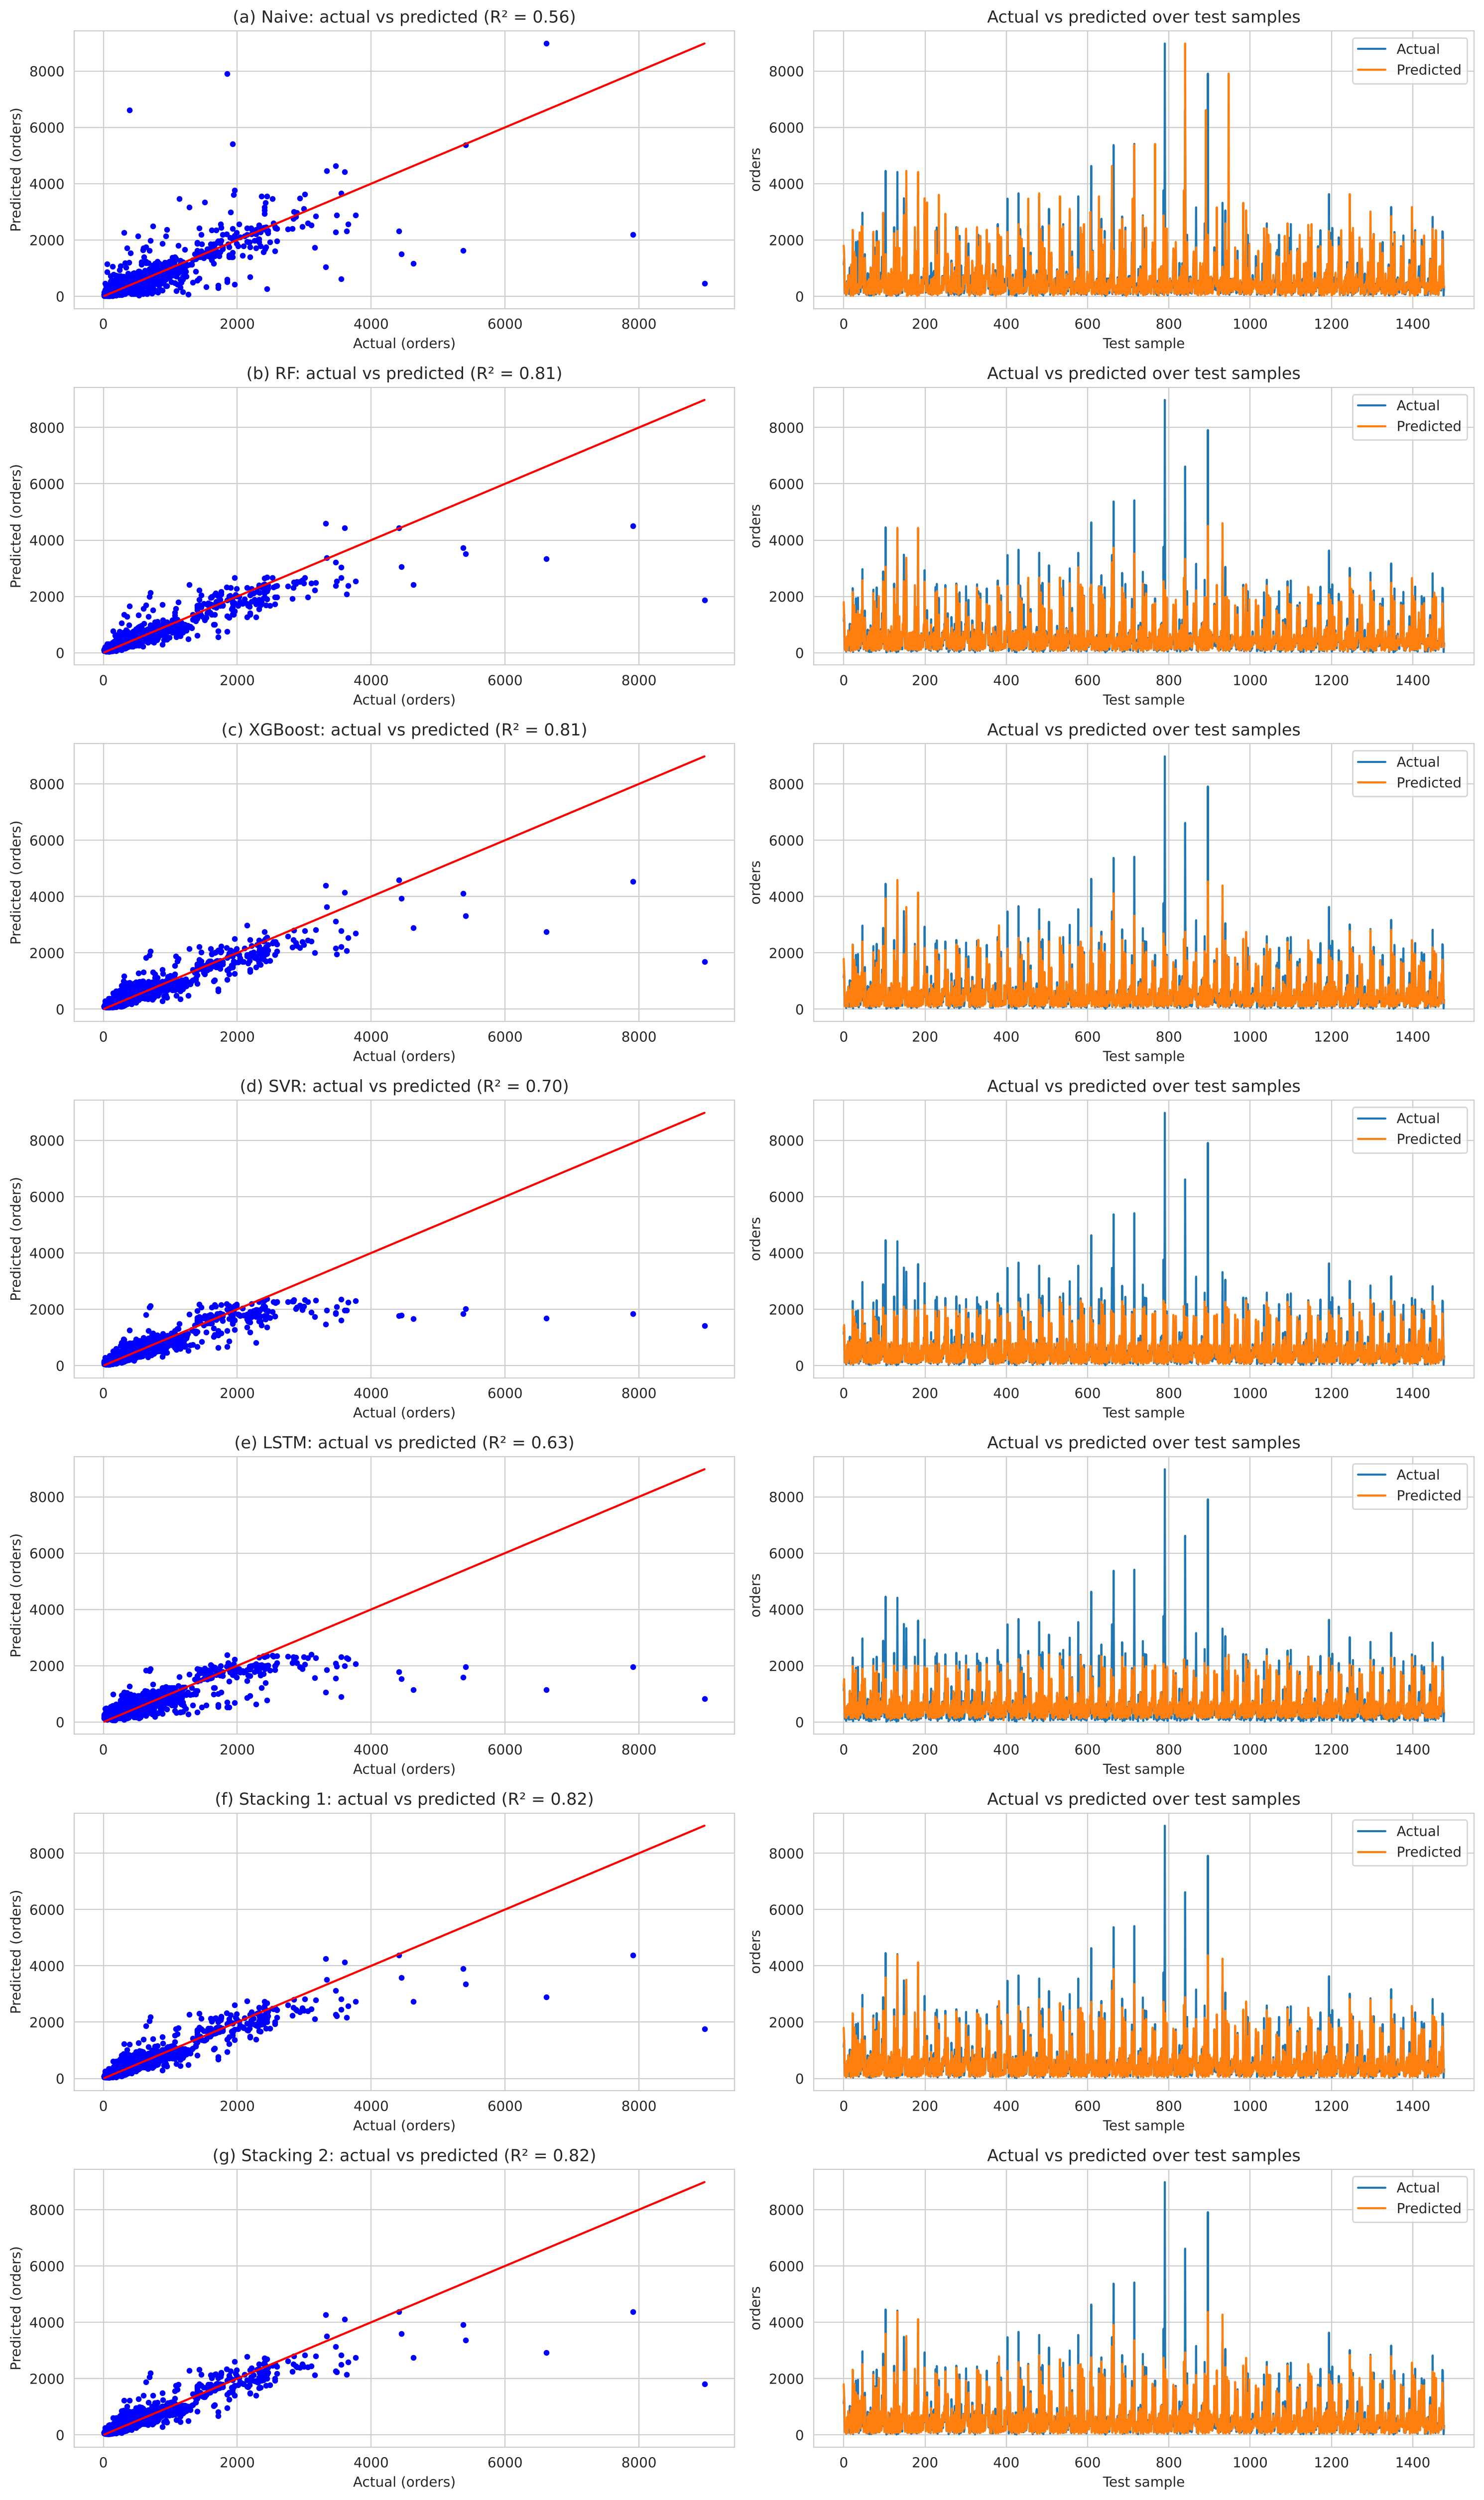

In [18]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdefgh'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",   # CHANGED: more panel letters, because the baseline adds a row
                   xlabel=f"Actual ({UNIT})", ylabel=f"Predicted ({UNIT})")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel=UNIT); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

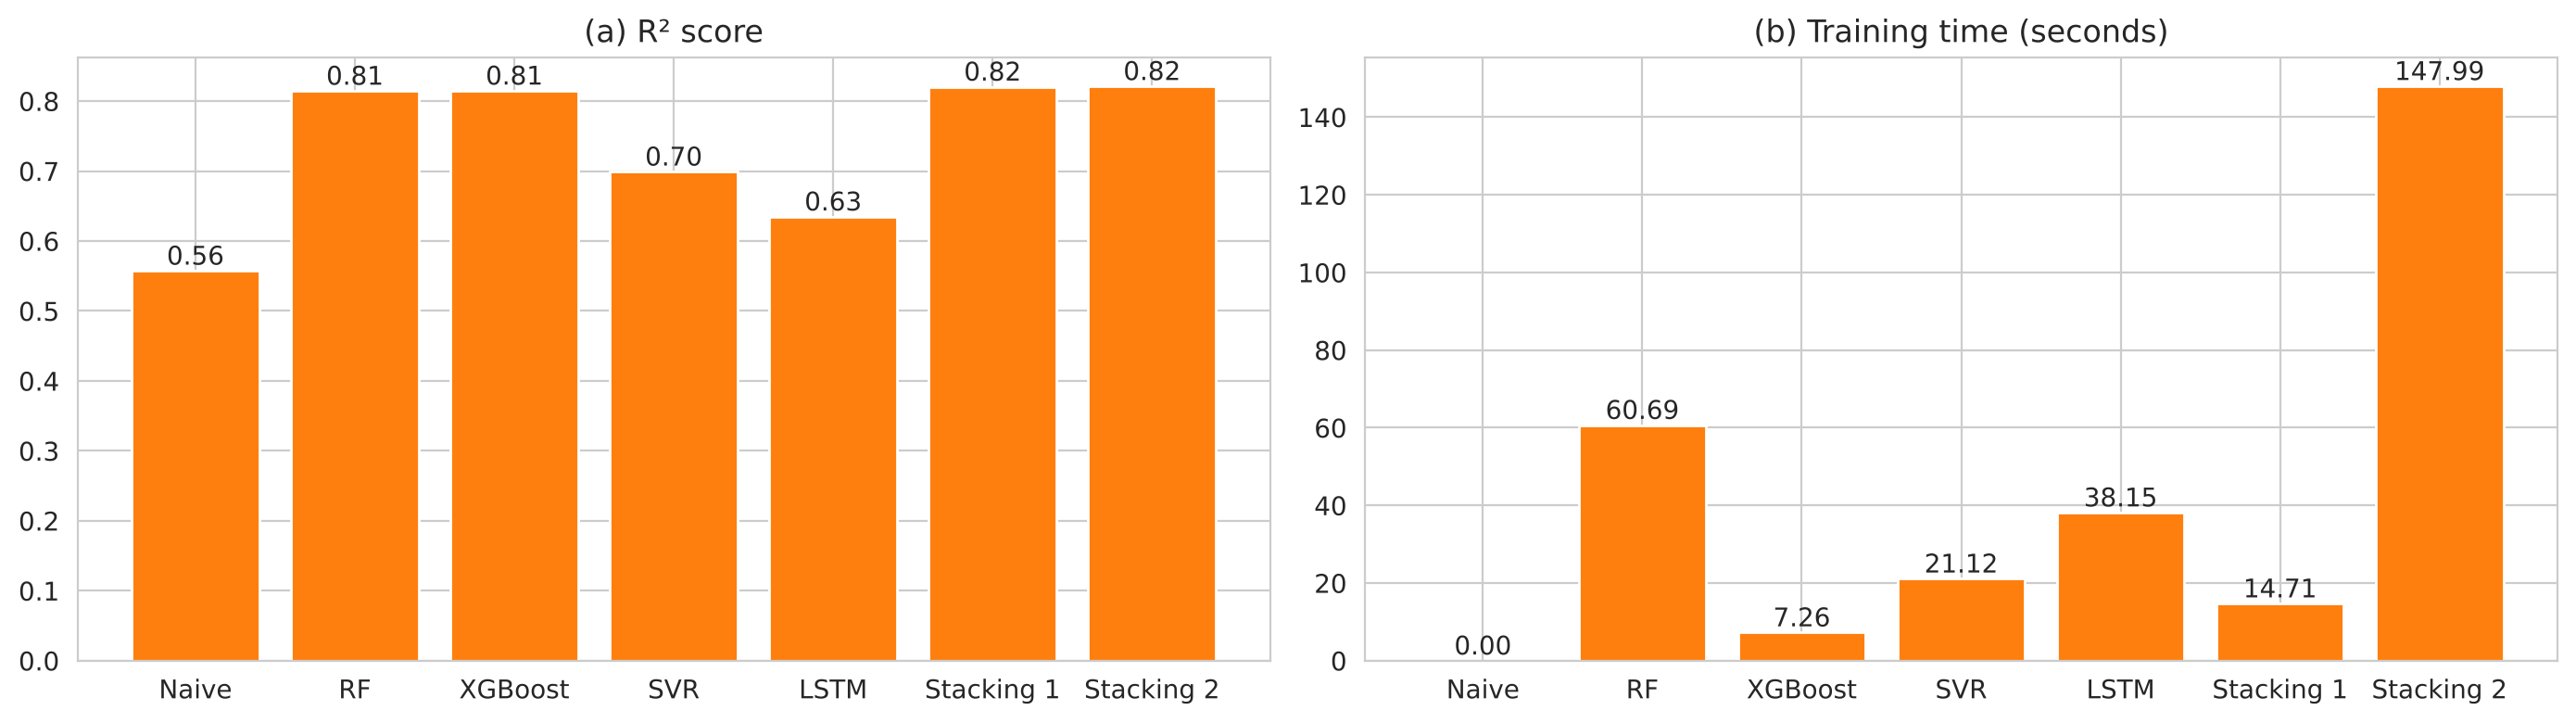

In [19]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 11. Stacking training time vs accuracy
This section is new. Both stacks are trained again with the original way of choosing alpha: a 5-fold GridSearchCV around the whole stack, which retrains all base models for every alpha value. The base models, settings and folds are the same as in Sections 8 and 9, so the only difference is how alpha is chosen.

- Stacking time: time to train the stack, including choosing alpha (and, for Stacking 2, training its LSTM).
- Total time: stacking time plus the grid search and training of the base models the stack reuses (their training times in the results table).
- Stacking 2 is compared with its LSTM trained once in both rows, so the only difference is how alpha is chosen; the original tuning with an LSTM retrained in every fold would need about 156 LSTM trainings. The last row is the Stacking 2 of Section 9, whose LSTM is retrained in every fold.

Why the new method is faster: alpha only changes the Ridge step, and Ridge only sees the base models' out-of-fold predictions. The original grid search retrained every base model for each alpha value and fold (25 times plus a final fit), which gives the same base-model predictions every time. RidgeCV compares the same alpha values with the same MAE scoring directly on those predictions, so the base models are only trained once per fold.

alpha  \
Stack                                    Meta-learner tuning                              
Stacking 1                               Original: GridSearchCV around the stack  100.0   
                                         New: RidgeCV meta-learner                100.0   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack  100.0   
                                         New: RidgeCV meta-learner                100.0   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)    100.0   

                                                                                      MAE  \
Stack                                    Meta-learner tuning                                
Stacking 1                               Original: GridSearchCV around the stack  141.738   
                                         New: RidgeCV meta-learner                141.738   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack  141.942   
                                         New: RidgeCV meta-learner                141.942   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)    142.199   

                                                                                     RMSE  \
Stack                                    Meta-learner tuning                                
Stacking 1                               Original: GridSearchCV around the stack  326.981   
                                         New: RidgeCV meta-learner                326.981   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack  329.422   
                                         New: RidgeCV meta-learner                329.422   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)    326.238   

                                                                                  SMAPE (%)  \
Stack                                    Meta-learner tuning                                  
Stacking 1                               Original: GridSearchCV around the stack     29.781   
                                         New: RidgeCV meta-learner                   29.781   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack     30.148   
                                         New: RidgeCV meta-learner                   30.148   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)       29.991   

                                                                                     R2  \
Stack                                    Meta-learner tuning                              
Stacking 1                               Original: GridSearchCV around the stack  0.821   
                                         New: RidgeCV meta-learner                0.821   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack  0.818   
                                         New: RidgeCV meta-learner                0.818   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)    0.821   

                                                                                  Stacking time (s)  \
Stack                                    Meta-learner tuning                                          
Stacking 1                               Original: GridSearchCV around the stack            299.479   
                                         New: RidgeCV meta-learner                           14.715   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack            295.816   
                                         New: RidgeCV meta-learner                           40.349   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)              147.986   

                                                                                  Total time (s)  
Stack          

Stacking 1: stacking time 299.5s -> 14.7s (20.4x faster), total 388.5s -> 103.8s, MAE 141.7 -> 141.7 (-0.00%)
Stacking 2, LSTM trained once: stacking time 295.8s -> 40.3s (7.3x faster), total 384.9s -> 129.4s, MAE 141.9 -> 141.9 (-0.00%)
Stacking 2, LSTM retrained in every fold (Section 9): stacking time 148.0s, total 237.1s, MAE 142.2


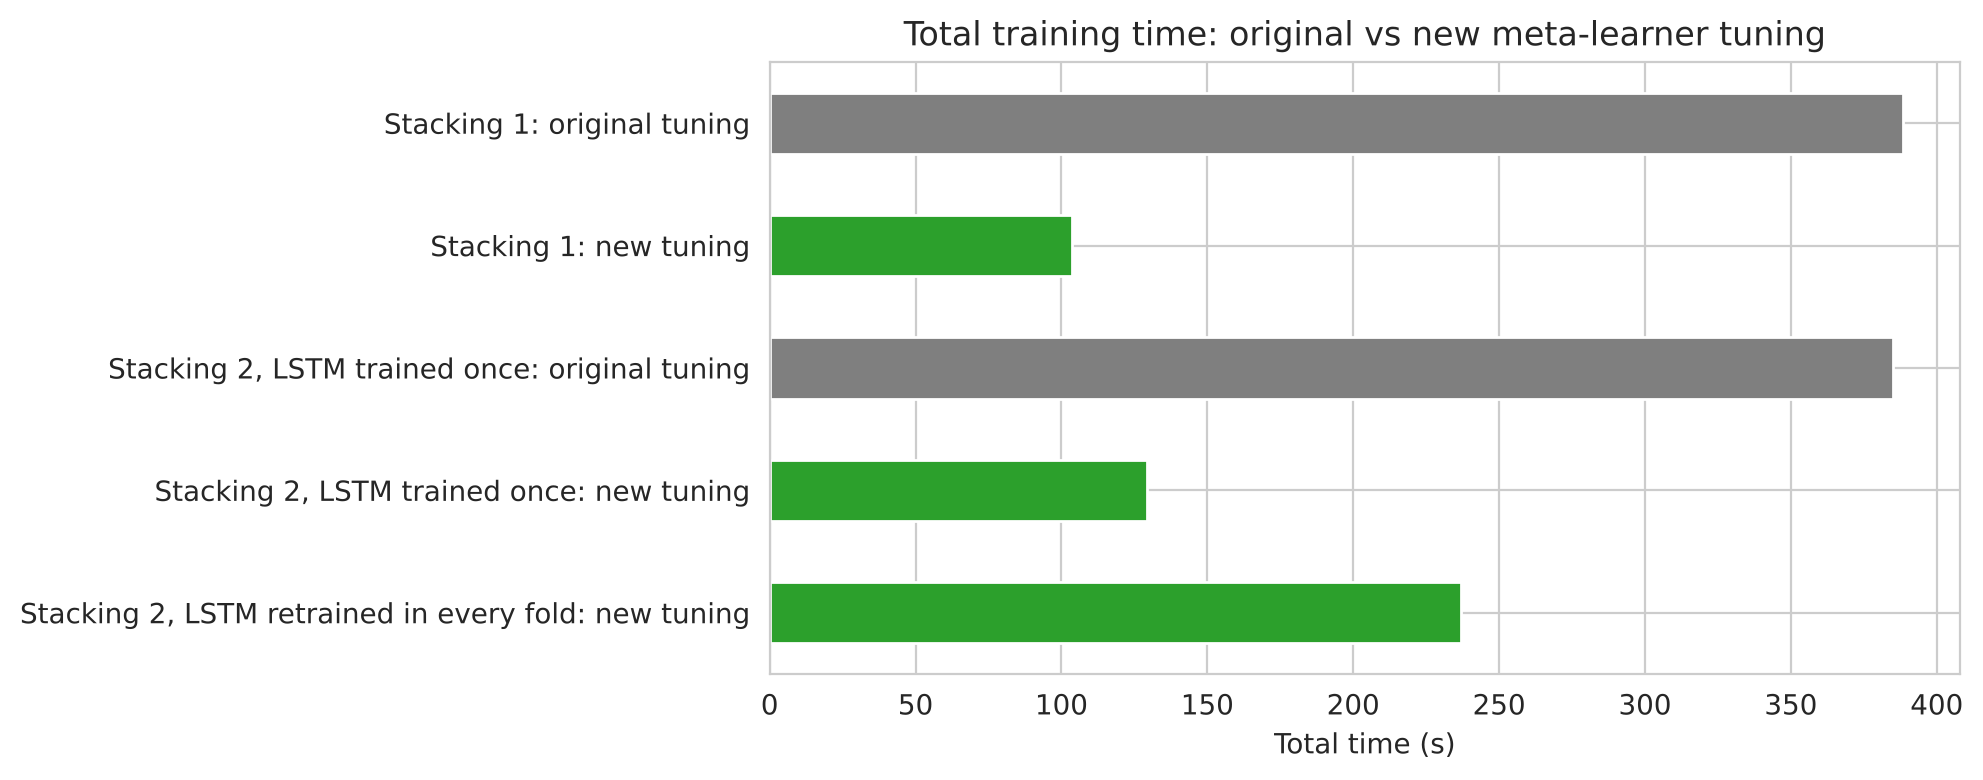

In [20]:
# CHANGED: new cell. Train both stacks with the original alpha tuning and compare with the new tuning
def original_tuning(estimators, X_fit):
    # Ridge meta-learner with alpha chosen by a GridSearchCV that retrains the whole stack for every alpha value
    stack = StackingRegressor(estimators=estimators, final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
    return GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                        cv=CV_FOLDS, scoring=SCORING).fit(X_fit, y_tr)

base_secs = {r["Model"]: r["Training time (s)"] for r in results}                 # grid search and training time of each model
reuse = base_secs["RF"] + base_secs["XGBoost"] + base_secs["SVR"]                  # base-model time shared by both stacks

t0 = time.time()
o1 = original_tuning([("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])], X_tr)
o1_secs = time.time() - t0

# CHANGED: Stacking 2 is compared with its LSTM trained once in both rows, so only the alpha tuning differs
lstm_once = Pipeline([("window", ColumnSlice(p, None)), ("model", WindowLSTM(p, "stack2_once"))])
s2_once = [("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_once)]

t0 = time.time()
PREFIT_LSTM["stack2_once"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)          # the single LSTM training
with parallel_backend("threading"):
    o2 = original_tuning(s2_once, Z_tr)
o2_secs = time.time() - t0
o2_pred = o2.predict(Z_te)

t0 = time.time()
PREFIT_LSTM["stack2_once"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)          # the single LSTM training
n2 = StackingRegressor(estimators=s2_once, final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
                       cv=CV_FOLDS, passthrough=False, n_jobs=-1)
with parallel_backend("threading"):
    n2.fit(Z_tr, y_tr)
n2_secs = time.time() - t0
n2_pred = n2.predict(Z_te)

# One row per stack and tuning method: chosen alpha, accuracy and time
S2_ONCE, S2_REFIT = "Stacking 2, LSTM trained once", "Stacking 2, LSTM retrained in every fold"
rows = []
for stack_name, tuning, pred, secs_, alpha in [
        ("Stacking 1", "Original: GridSearchCV around the stack", o1.predict(X_te), o1_secs, o1.best_params_["final_estimator__alpha"]),
        ("Stacking 1", "New: RidgeCV meta-learner", preds["Stacking 1"], base_secs["Stacking 1 (RF, XGBoost, SVR)"], s1.final_estimator_.alpha_),
        (S2_ONCE, "Original: GridSearchCV around the stack", o2_pred, o2_secs, o2.best_params_["final_estimator__alpha"]),
        (S2_ONCE, "New: RidgeCV meta-learner", n2_pred, n2_secs, n2.final_estimator_.alpha_),
        (S2_REFIT, "New: RidgeCV meta-learner (Section 9)", preds["Stacking 2"], base_secs["Stacking 2 (RF, XGBoost, SVR, LSTM)"], s2.final_estimator_.alpha_)]:
    m = evaluate(stack_name, y_te, pred, secs_)
    rows.append({"Stack": stack_name, "Meta-learner tuning": tuning, "alpha": alpha,
                 "MAE": m["MAE"], "RMSE": m["RMSE"], "SMAPE (%)": m["SMAPE (%)"], "R2": m["R2"],
                 "Stacking time (s)": secs_, "Total time (s)": secs_ + reuse})
ro1 = pd.DataFrame(rows).set_index(["Stack", "Meta-learner tuning"])
display(ro1.round(3))

# Time saved and change in MAE for each stack
for s in ["Stacking 1", S2_ONCE]:
    old, new = ro1.loc[s].iloc[0], ro1.loc[s].iloc[1]
    print(f"{s}: stacking time {old['Stacking time (s)']:.1f}s -> {new['Stacking time (s)']:.1f}s "
          f"({old['Stacking time (s)'] / new['Stacking time (s)']:.1f}x faster), total {old['Total time (s)']:.1f}s -> {new['Total time (s)']:.1f}s, "
          f"MAE {old['MAE']:.1f} -> {new['MAE']:.1f} ({(new['MAE'] / old['MAE'] - 1) * 100:+.2f}%)")

refit = ro1.loc[S2_REFIT].iloc[0]
print(f"{S2_REFIT} (Section 9): stacking time {refit['Stacking time (s)']:.1f}s, total {refit['Total time (s)']:.1f}s, MAE {refit['MAE']:.1f}")

# Total training time of each stack and tuning method
labels = [f"{s}: {t.split(':')[0].lower()} tuning" for s, t in ro1.index]
ax = pd.Series(ro1["Total time (s)"].values, index=labels).plot(
    kind="barh", figsize=(10, 4), color=["tab:gray" if t.startswith("Original") else "tab:green" for _, t in ro1.index])
ax.invert_yaxis(); ax.set(xlabel="Total time (s)", title="Total training time: original vs new meta-learner tuning")
plt.tight_layout(); plt.show()

## 12. Explainability (SHAP and LIME)
This section is new. It explains the forecasts of both stacking ensembles. SHAP and LIME only use a model's predictions, so they explain each stack as a whole rather than its base models separately.

- SHAP splits each forecast into a contribution from every input. A positive contribution raises the forecast and a negative one lowers it. The contributions add up to the difference between that forecast and the average forecast over a reference sample of 100 training rows (the same rows for both stacks). SHAP is computed for `SHAP_ROWS` test rows chosen at random, to keep the run time manageable.
- The one-hot columns of each categorical input (for example the 51 `meal_id` columns) are added together, so every original variable gets a single contribution.
- In Stacking 2 the LSTM's input is the window of the 10 previous records of the same meal. SHAP treats the whole window as one input, called "LSTM window (previous 10 records)".
- LIME fits a simple linear model to a stack's predictions around one row and reports the inputs with the largest effect. It is used to check the SHAP explanations of two example rows. LIME's conditions refer to the scaled inputs (0 to 1). For Stacking 2, LIME keeps the 10-record window fixed at the row's own window and varies the other inputs.

In [21]:
# CHANGED: new cell. Install SHAP and LIME if they are missing (e.g. on Colab), then import them
import importlib.util
if importlib.util.find_spec("shap") is None or importlib.util.find_spec("lime") is None:
    !pip install -q shap lime
import shap
from lime.lime_tabular import LimeTabularExplainer

In [22]:
# CHANGED: new cell. SHAP values of both stacks for a random sample of test rows
WINDOW = "LSTM window (previous 10 records)"
W_flat = W_all.reshape(len(y), -1)

def s2_predict(M):
    # M holds the row features plus a row number; that row's 10-record window is looked up and passed to Stacking 2
    rows = np.clip(np.round(M[:, -1]).astype(int), 0, len(y) - 1)
    return s2.predict(np.hstack([M[:, :-1], W_flat[rows]]))

ex = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(idx_te), min(SHAP_ROWS, len(idx_te)), replace=False))   # explained test rows
MODELS = {
    "Stacking 1": {"predict": s1.predict, "X_tr": X_tr, "X_te": X_te[ex], "names": list(X.columns)},
    "Stacking 2": {"predict": s2_predict, "X_tr": np.column_stack([X_tr, idx_tr]), "X_te": np.column_stack([X_te, idx_te])[ex],
                   "names": list(X.columns) + [WINDOW]},
}
bg = np.random.RandomState(RANDOM_STATE).choice(len(idx_tr), 100, replace=False)   # the same 100 reference rows for both stacks

xai = {}
for name, m in MODELS.items():
    explainer = shap.PermutationExplainer(m["predict"], m["X_tr"][bg], feature_names=m["names"], seed=RANDOM_STATE)
    t0 = time.time()
    sv = explainer(m["X_te"])
    # Add the one-hot columns of each categorical input together, so each original variable has one contribution
    groups = {}
    for i, col in enumerate(m["names"]):
        groups.setdefault(next((c for c in CAT_COLS if col.startswith(c + "_")), col), []).append(i)
    var_shap = np.column_stack([sv.values[:, cols].sum(axis=1) for cols in groups.values()])
    xai[name] = {"sv": sv, "vars": list(groups), "shap": var_shap}
    # Check: base value + contributions should equal the stack's forecast for every explained test row
    gap = np.abs(sv.base_values + var_shap.sum(axis=1) - m["predict"](m["X_te"])).max()
    print(f"{name}: SHAP values for {len(m['X_te'])} test rows in {time.time() - t0:.1f}s | largest gap to the forecast {gap:.3f} {UNIT}")

PermutationExplainer explainer:   3%|▎         | 3/100 [00:00<?, ?it/s]

PermutationExplainer explainer:   5%|▌         | 5/100 [00:13<02:45,  1.75s/it]

PermutationExplainer explainer:   6%|▌         | 6/100 [00:17<03:46,  2.41s/it]

PermutationExplainer explainer:   7%|▋         | 7/100 [00:20<04:09,  2.69s/it]

PermutationExplainer explainer:   8%|▊         | 8/100 [00:23<04:31,  2.95s/it]

PermutationExplainer explainer:   9%|▉         | 9/100 [00:27<04:42,  3.11s/it]

... (190 outputs left out)

PermutationExplainer explainer: 100%|██████████| 100/100 [08:58<00:00,  5.60s/it]

PermutationExplainer explainer: 101it [09:04,  5.71s/it]                         

PermutationExplainer explainer: 101it [09:04,  5.56s/it]

Stacking 2: SHAP values for 100 test rows in 544.7s | largest gap to the forecast 0.000 orders


### Global importance
Average size of each variable's contribution over the explained test rows (mean absolute SHAP value, in orders) and its share of the total, for both stacks. The beeswarm plots show the individual input columns: each dot is one test row, its position is the contribution and its colour is the input value (red = high, or category present). The LSTM window is left out of the Stacking 2 beeswarm because it has no single value to colour by.

Mean |SHAP| (orders)             Share (%)  \
                                            Stacking 1 Stacking 2 Stacking 1   
checkout_price                                  195.51     199.53      23.58   
Orders_last_two_weeks                           131.21     130.87      15.82   
meal_id                                         127.78     141.01      15.41   
Orders_last_four_weeks                          102.86     107.08      12.40   
Orders_last_week                                 91.40      89.74      11.02   
emailer_for_promotion                            88.05      91.16      10.62   
base_price                                       58.00      55.32       6.99   
homepage_featured                                34.43      36.90       4.15   
LSTM window (previous 10 records)                 0.00      21.92       0.00   

                                              
                                  Stacking 2  
checkout_price                         22.84  
Orders_last_two_weeks                  14.98  
meal_id                                16.14  
Orders_last_four_weeks                 12.26  
Orders_last_week                       10.27  
emailer_for_promotion                  10.44  
base_price                              6.33  
homepage_featured                       4.22  
LSTM window (previous 10 records)       2.51

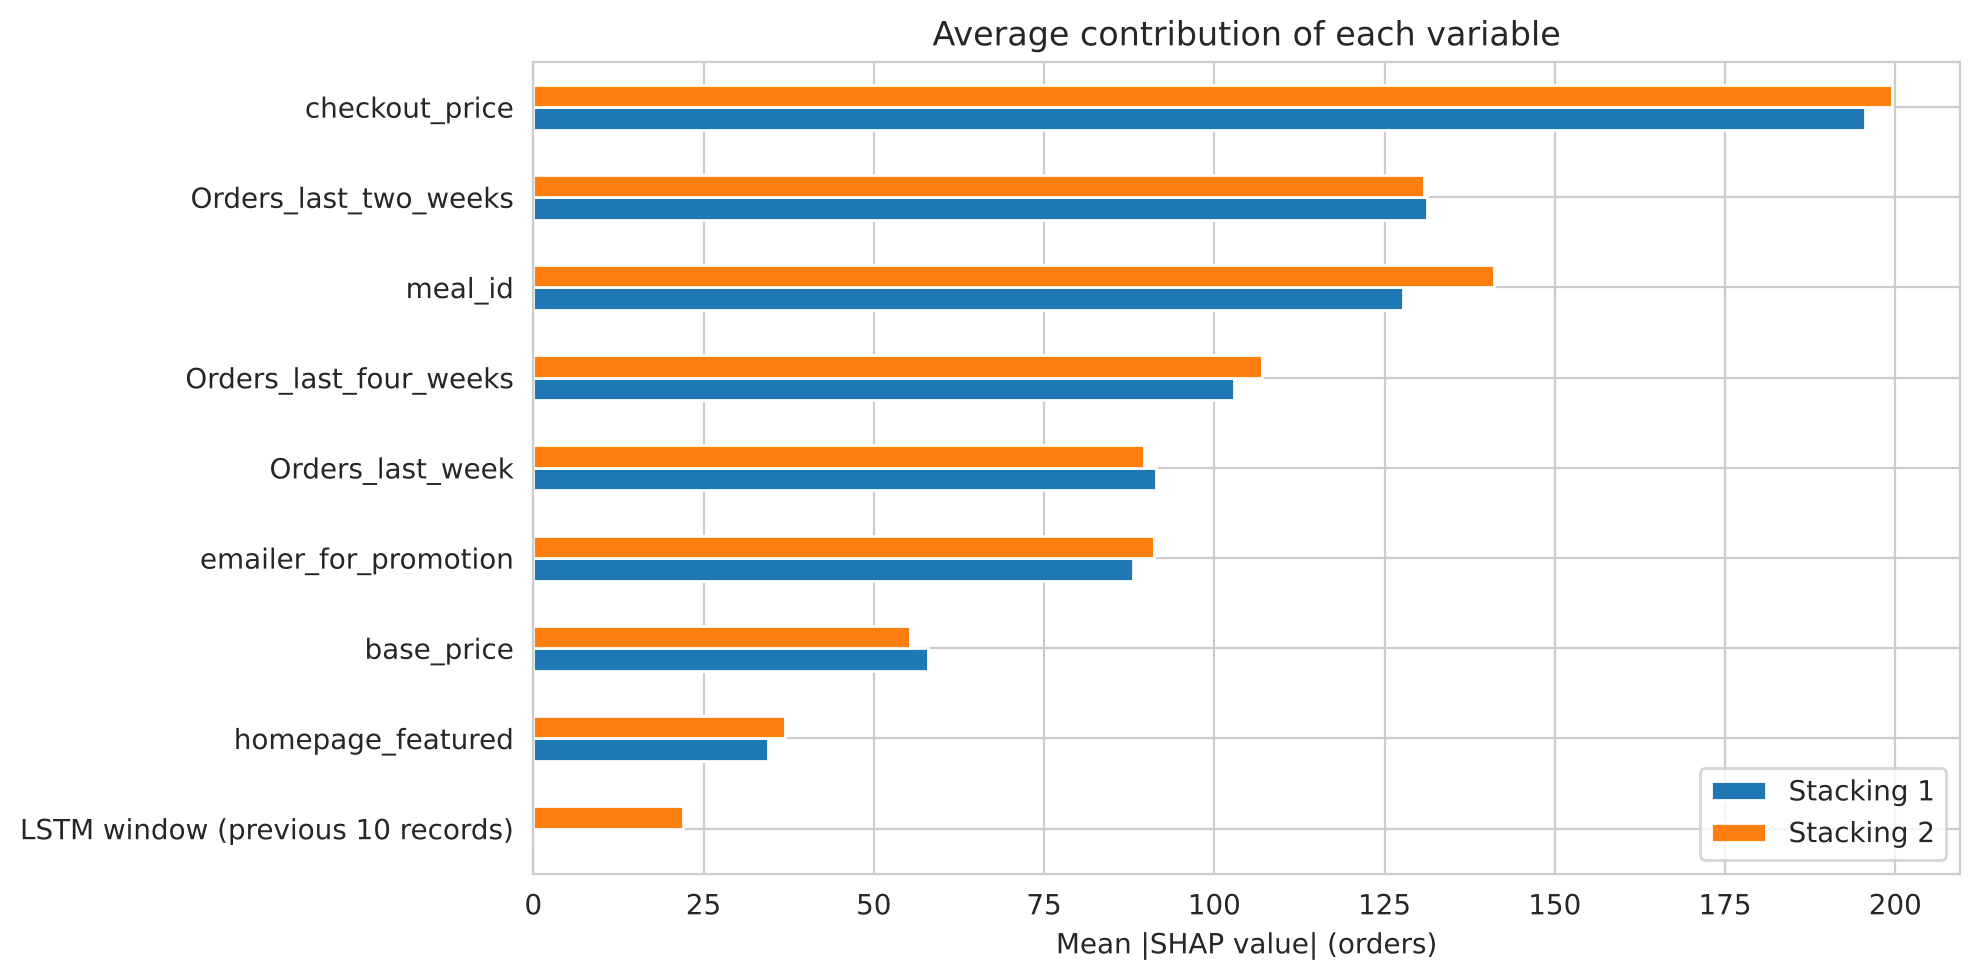

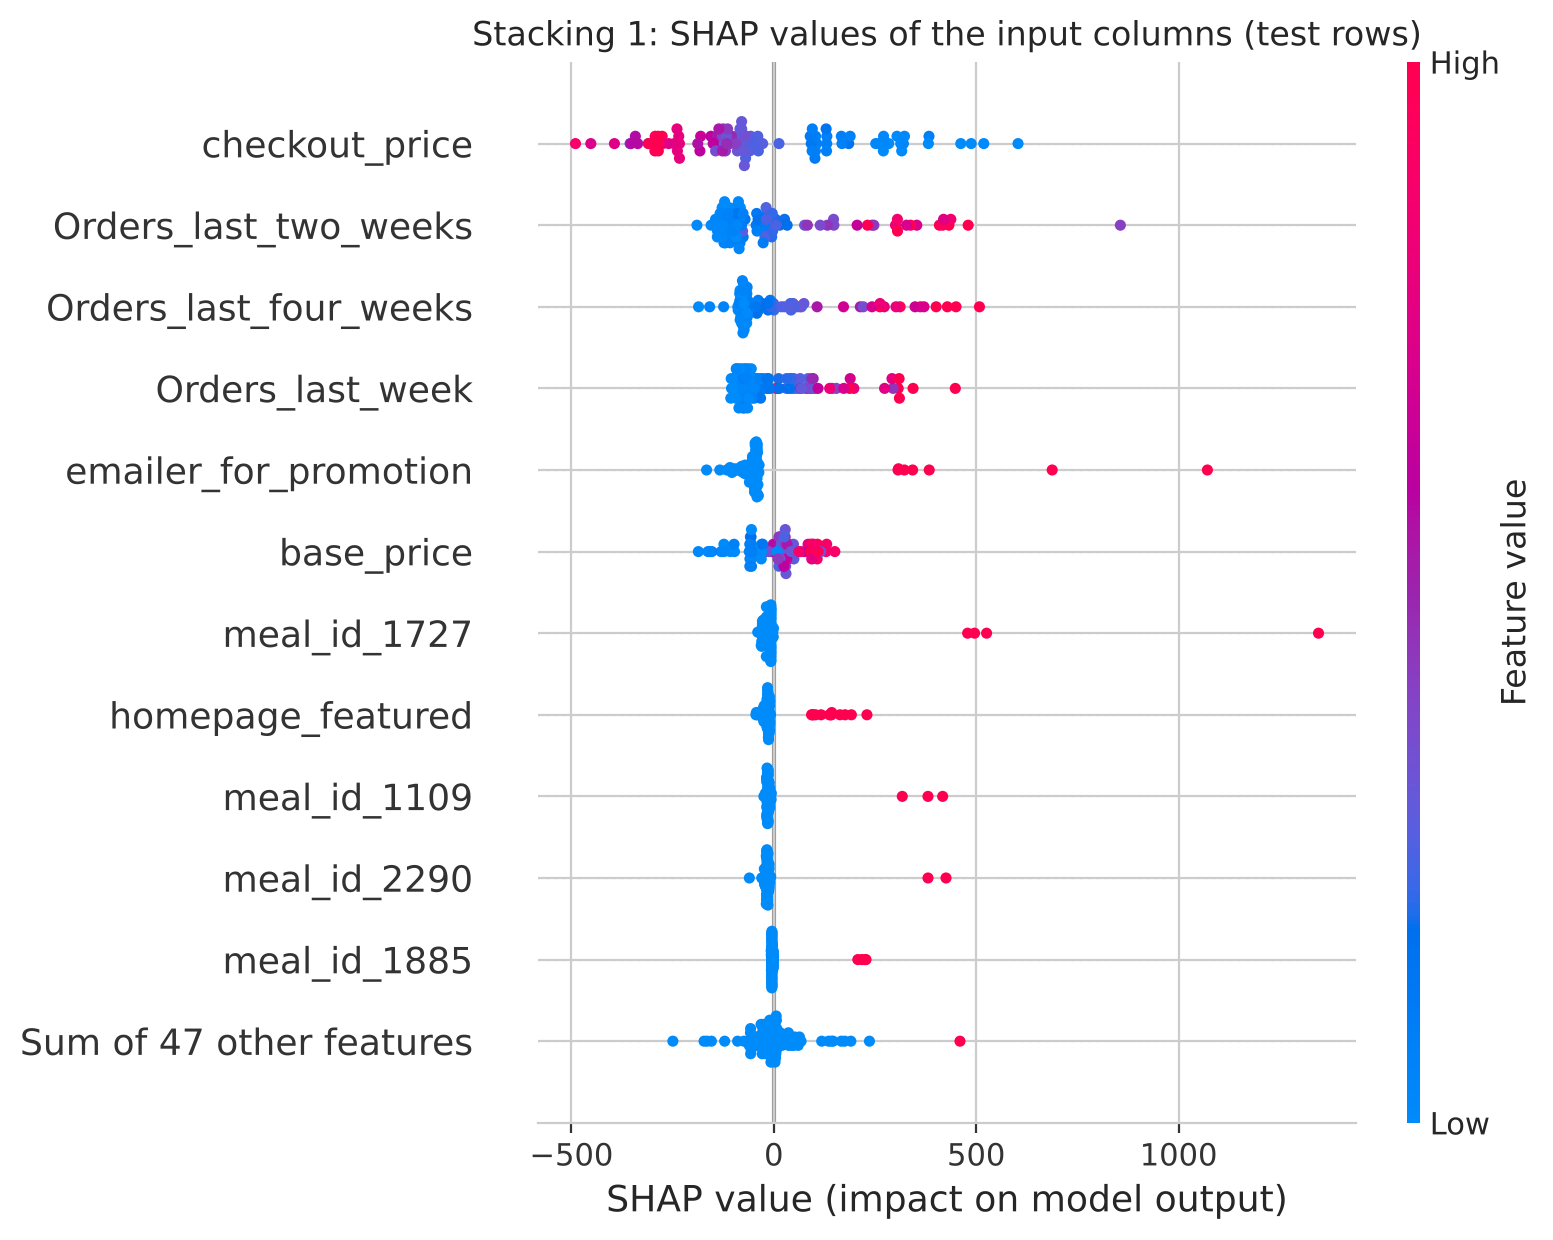

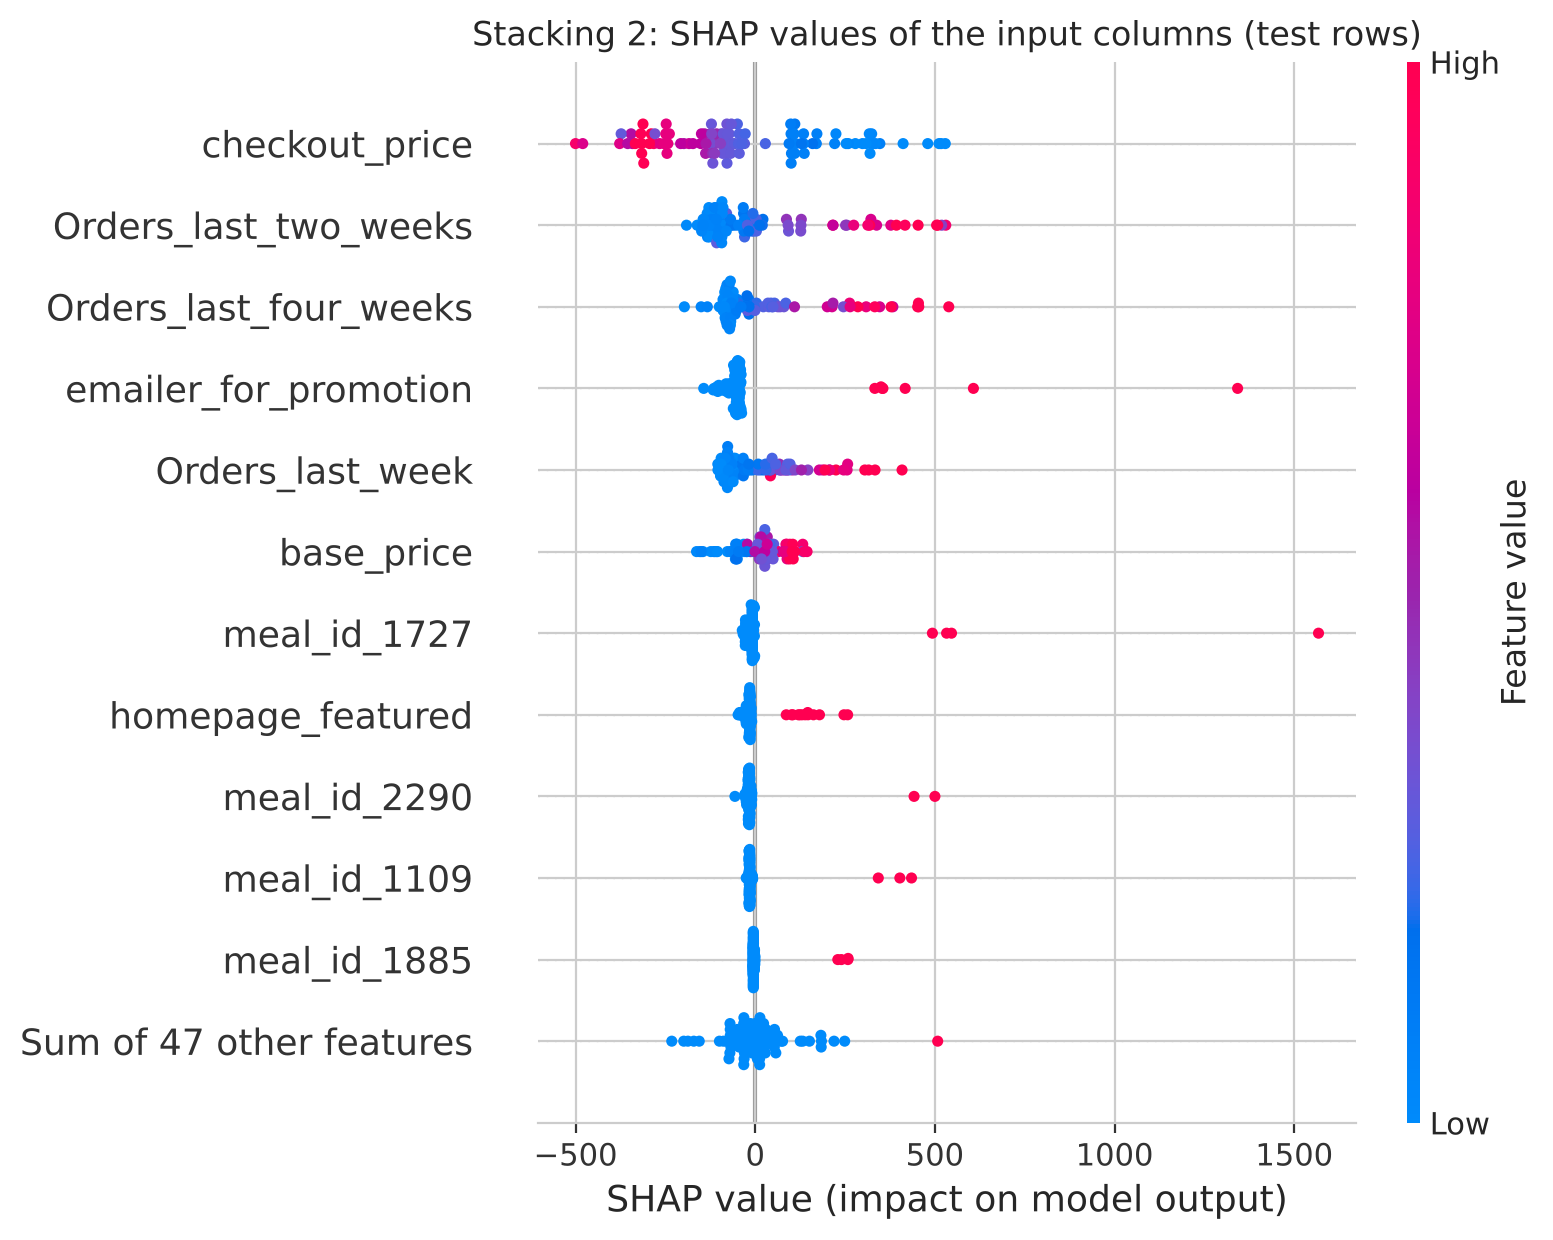

In [23]:
# CHANGED: new cell. Global importance of each original variable for both stacks
imp = pd.concat({name: pd.Series(np.abs(r["shap"]).mean(axis=0), index=r["vars"]) for name, r in xai.items()}, axis=1)
imp = imp.fillna(0).sort_values("Stacking 1", ascending=False)
table = pd.concat({f"Mean |SHAP| ({UNIT})": imp, "Share (%)": imp / imp.sum() * 100}, axis=1)
display(table.round(2))

ax = imp.iloc[::-1].plot(kind="barh", figsize=(10, 5), color=["tab:blue", "tab:orange"])
ax.set(xlabel=f"Mean |SHAP value| ({UNIT})", title="Average contribution of each variable")
plt.tight_layout(); plt.show()

for name, r in xai.items():
    cols = [i for i, n in enumerate(MODELS[name]["names"]) if n != WINDOW]
    shap.plots.beeswarm(r["sv"][:, cols], max_display=12, show=False)
    plt.title(f"{name}: SHAP values of the input columns (test rows)"); plt.tight_layout(); plt.show()

### Local explanations of two test rows
Two example rows are explained with both stacks: the explained test rows with the highest and the lowest Stacking 1 forecast. The waterfall plots start from the average forecast and add each variable's contribution to reach that row's forecast. The LIME tables list the conditions with the largest effect on the same forecasts, and the last line for each stack compares the three most important variables from both methods.

Highest forecast: week 135, meal 1727, price 315.25, e-mail 1, homepage 1 | actual 3,321 orders


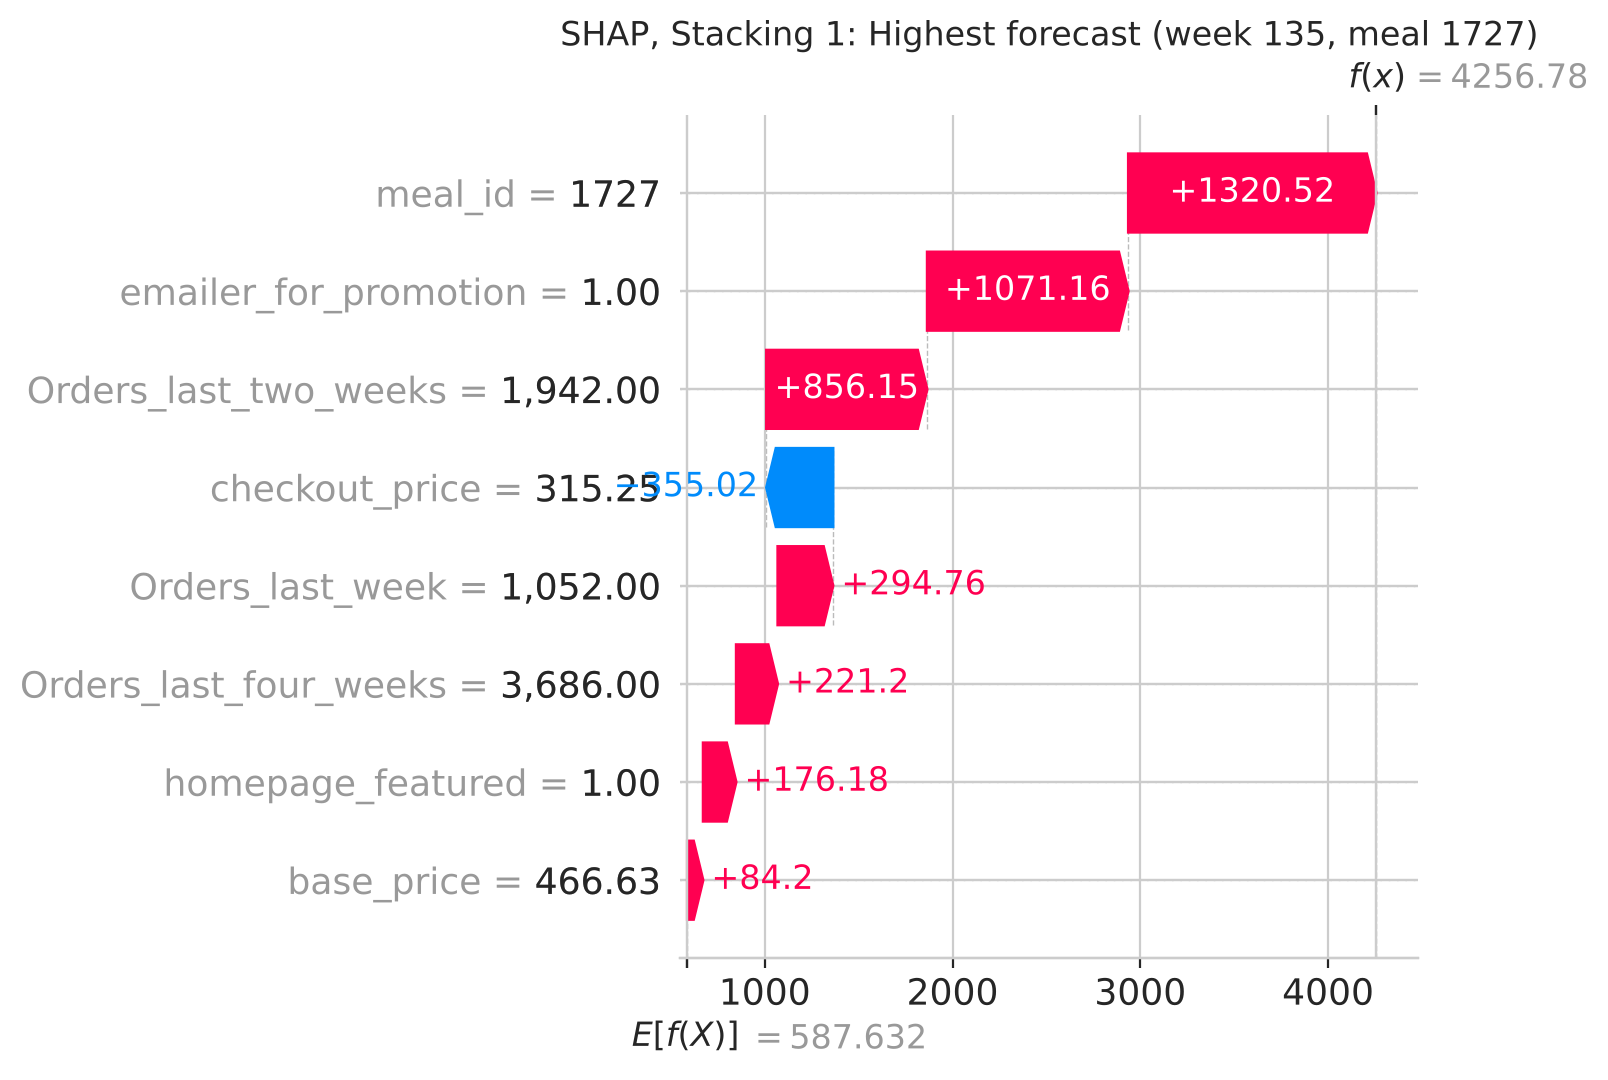

LIME, Stacking 1: Highest forecast | forecast 4,257 orders


,LIME condition (scaled inputs),Effect (orders)
0,meal_id_1727 > 0.00,708.2
1,emailer_for_promotion > 0.00,549.4
2,meal_id_1109 <= 0.00,-529.5
3,meal_id_2707 <= 0.00,-424.4
4,meal_id_2290 <= 0.00,-360.3
5,Orders_last_two_weeks > 0.10,351.5
6,Orders_last_week > 0.08,301.7
7,Orders_last_four_weeks > 0.13,286.2


Top 3 variables, Stacking 1 - SHAP: ['meal_id', 'emailer_for_promotion', 'Orders_last_two_weeks'] | LIME: ['meal_id', 'emailer_for_promotion', 'Orders_last_two_weeks']



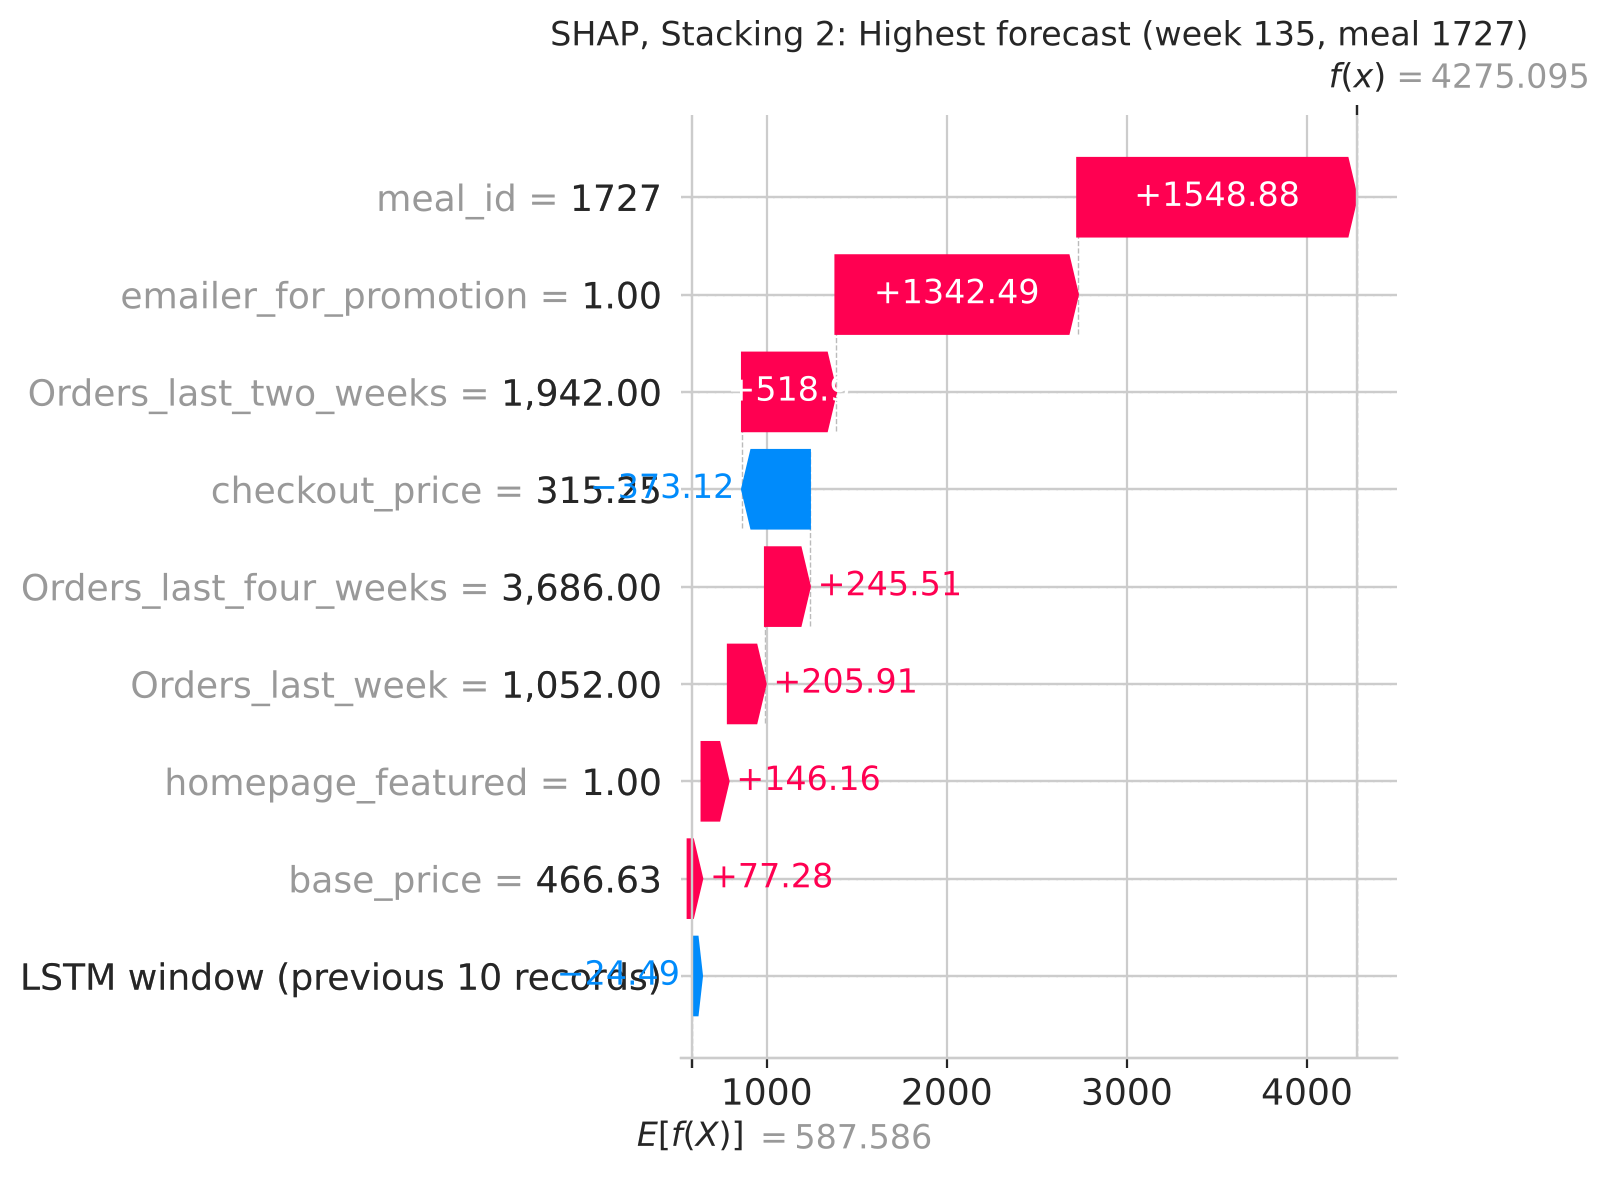

LIME, Stacking 2: Highest forecast | forecast 4,275 orders


,LIME condition (scaled inputs),Effect (orders)
0,meal_id_1727 > 0.00,701.3
1,emailer_for_promotion > 0.00,599.2
2,meal_id_2290 <= 0.00,-474.2
3,meal_id_1109 <= 0.00,-454.8
4,meal_id_2707 <= 0.00,-337.1
5,Orders_last_two_weeks > 0.10,332.9
6,meal_id_1885 <= 0.00,-305.0
7,Orders_last_week > 0.08,302.2


Top 3 variables, Stacking 2 - SHAP: ['meal_id', 'emailer_for_promotion', 'Orders_last_two_weeks'] | LIME: ['meal_id', 'emailer_for_promotion', 'Orders_last_two_weeks']

Lowest forecast: week 140, meal 1770, price 485.03, e-mail 0, homepage 0 | actual 80 orders


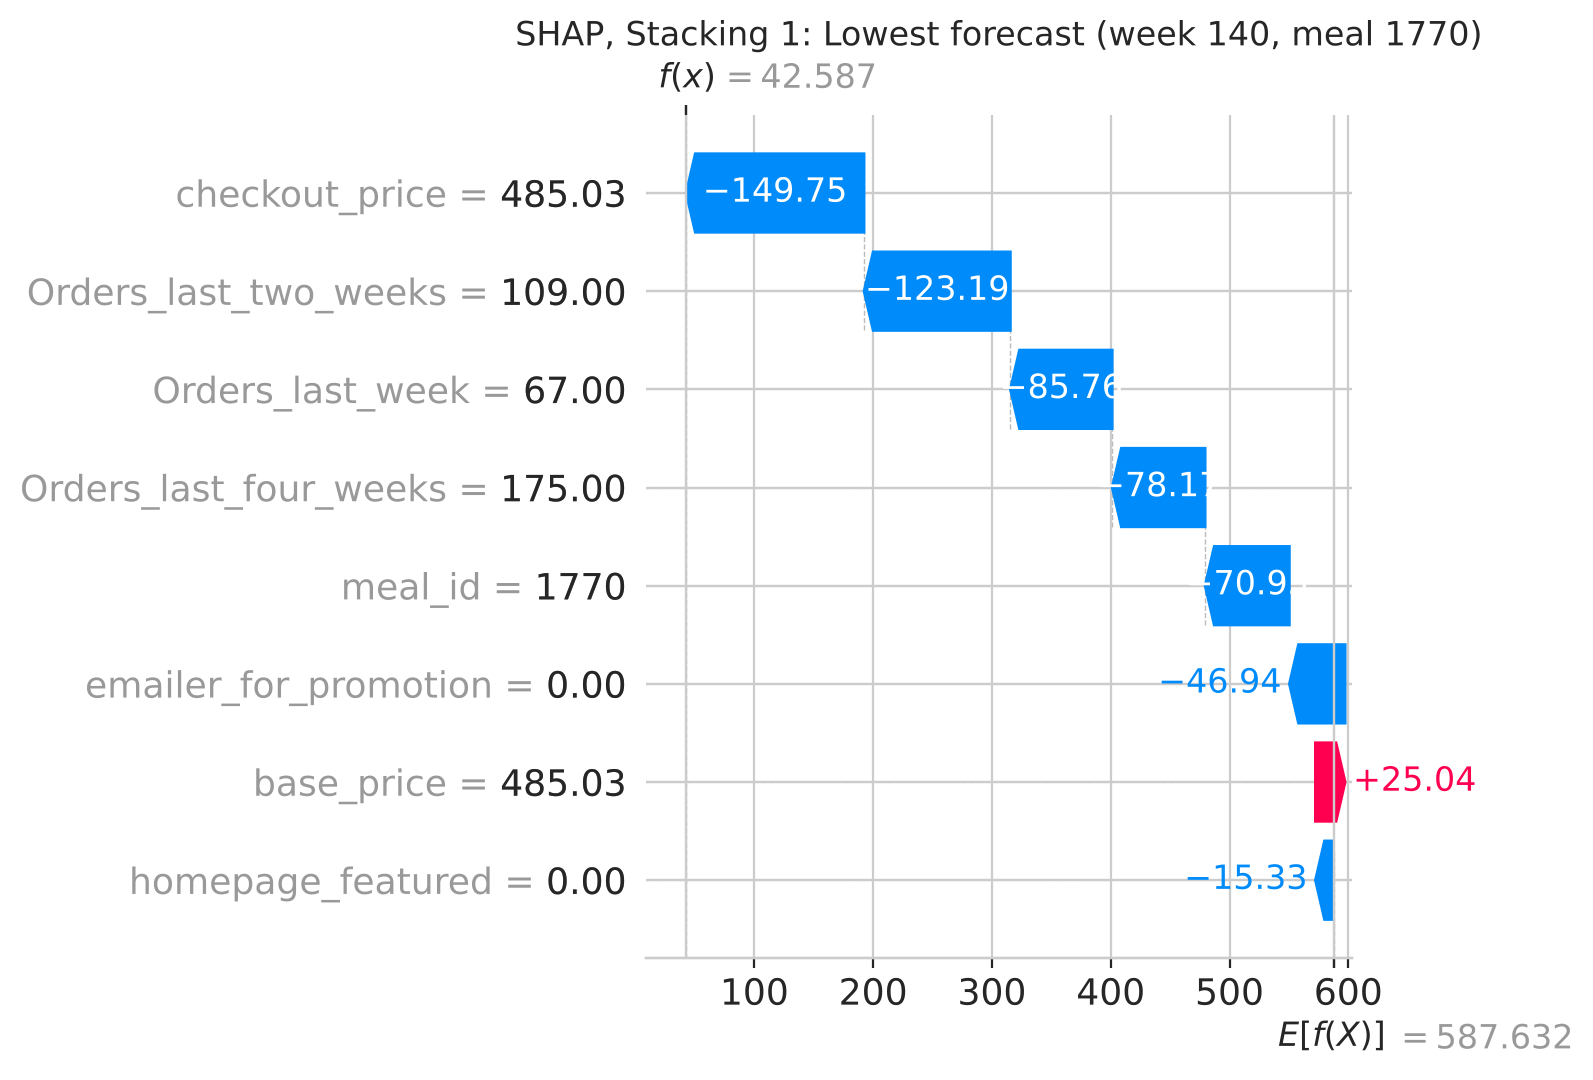

LIME, Stacking 1: Lowest forecast | forecast 43 orders


,LIME condition (scaled inputs),Effect (orders)
0,meal_id_1727 <= 0.00,-725.5
1,emailer_for_promotion <= 0.00,-550.7
2,meal_id_1109 <= 0.00,-484.0
3,meal_id_2707 <= 0.00,-457.1
4,meal_id_2290 <= 0.00,-353.4
5,checkout_price > 0.55,-319.9
6,meal_id_2826 <= 0.00,-281.9
7,meal_id_2104 <= 0.00,-260.7


Top 3 variables, Stacking 1 - SHAP: ['checkout_price', 'Orders_last_two_weeks', 'Orders_last_week'] | LIME: ['meal_id', 'emailer_for_promotion', 'checkout_price']



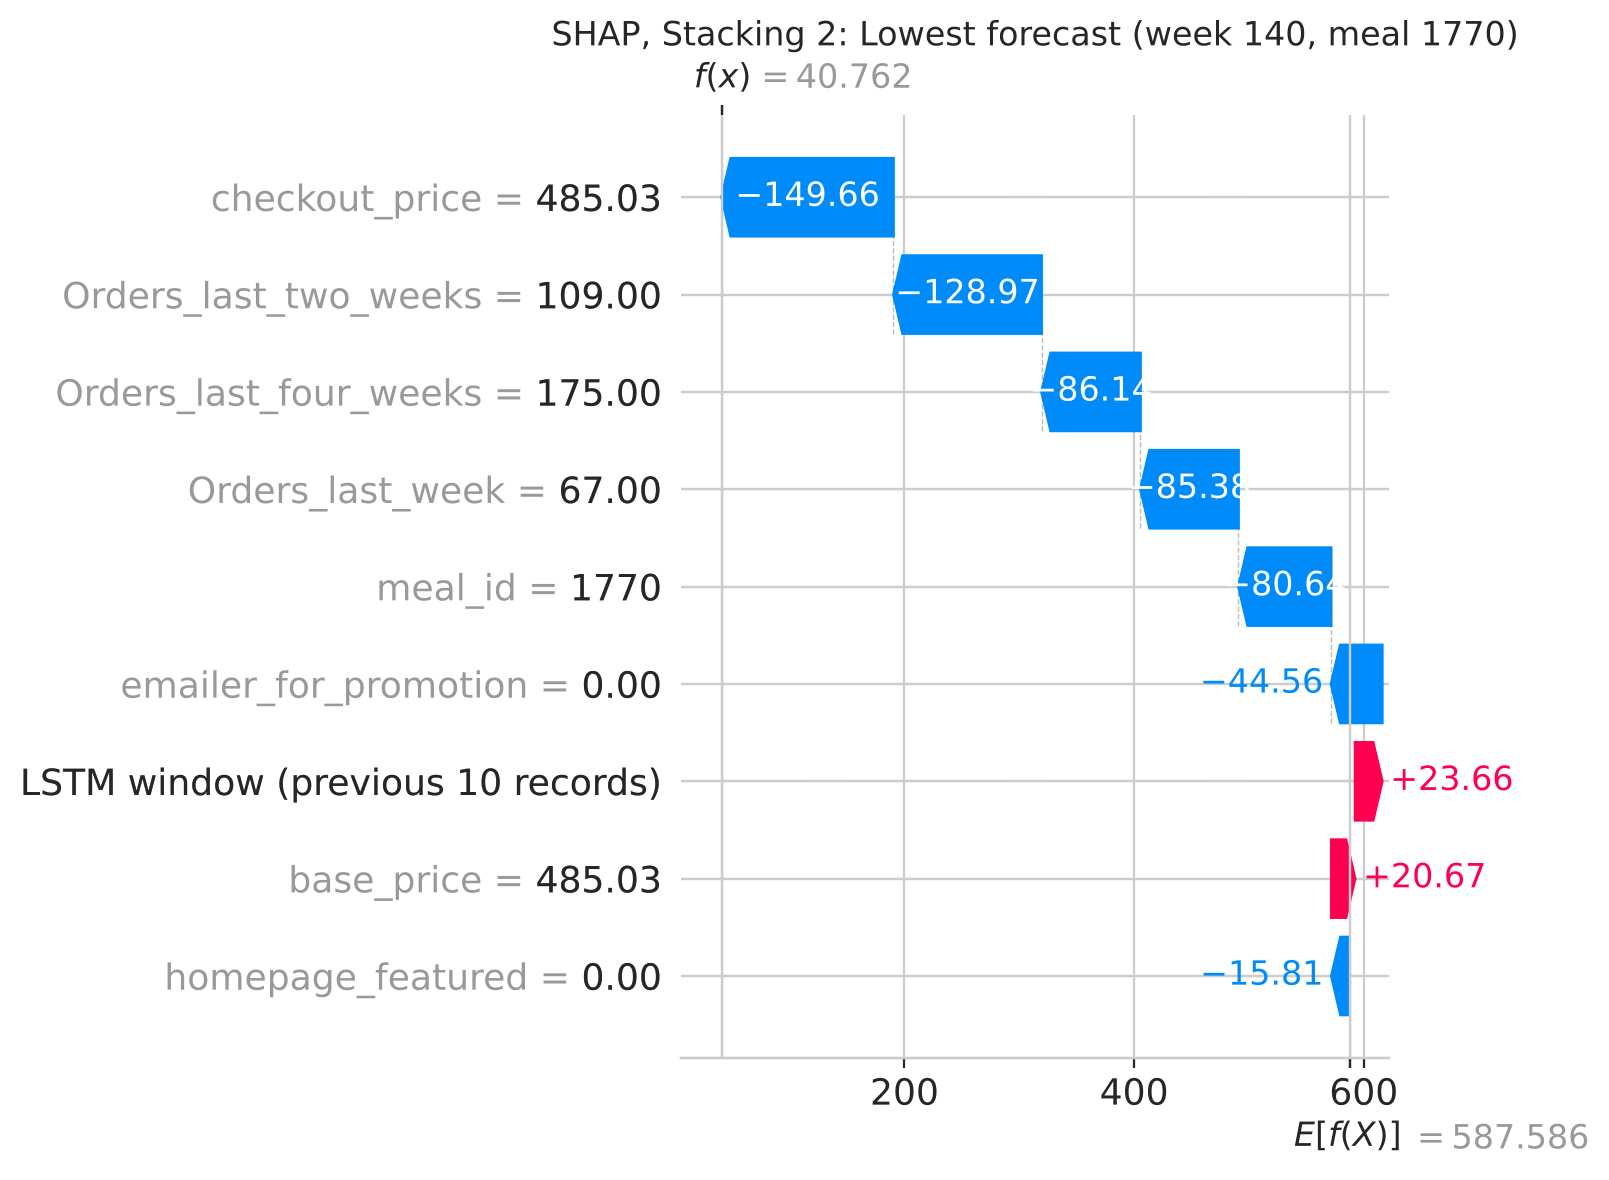

LIME, Stacking 2: Lowest forecast | forecast 41 orders


,LIME condition (scaled inputs),Effect (orders)
0,meal_id_1727 <= 0.00,-600.6
1,emailer_for_promotion <= 0.00,-587.4
2,meal_id_1109 <= 0.00,-479.1
3,meal_id_2290 <= 0.00,-439.6
4,meal_id_2707 <= 0.00,-393.8
5,checkout_price > 0.55,-351.8
6,meal_id_2826 <= 0.00,-295.7
7,meal_id_1885 <= 0.00,-228.3


Top 3 variables, Stacking 2 - SHAP: ['checkout_price', 'Orders_last_two_weeks', 'Orders_last_four_weeks'] | LIME: ['meal_id', 'emailer_for_promotion', 'checkout_price']



In [24]:
# CHANGED: new cell. SHAP waterfall plots and LIME explanations of two example test rows for both stacks
s1_ex = preds["Stacking 1"][ex]
examples = {"Highest forecast": int(np.argmax(s1_ex)), "Lowest forecast": int(np.argmin(s1_ex))}   # positions within the explained rows
lime_explainer = LimeTabularExplainer(X_tr, feature_names=list(X.columns), mode="regression", random_state=RANDOM_STATE)

def label(var, row):
    # Variable name with its original value in that row, for the plot labels
    if var == WINDOW:
        return var
    value = df[var].iloc[row] if var in CAT_COLS else X[var].iloc[row]
    return f"{var} = {value}" if var in CAT_COLS else f"{var} = {value:,.2f}"

for title, r in examples.items():
    t = ex[r]                       # position in the test set
    row = df.iloc[idx_te[t]]
    print(f"{title}: week {row.week}, meal {row.meal_id}, price {row.checkout_price:.2f}, e-mail {row.emailer_for_promotion}, "
          f"homepage {row.homepage_featured} | actual {y_te[t]:,.0f} {UNIT}")
    for name, res in xai.items():
        # SHAP waterfall with one bar per original variable
        exp = shap.Explanation(values=res["shap"][r], base_values=res["sv"].base_values[r],
                               feature_names=[label(v, idx_te[t]) for v in res["vars"]])
        shap.plots.waterfall(exp, max_display=10, show=False)
        plt.title(f"SHAP, {name}: {title} (week {row.week}, meal {row.meal_id})"); plt.tight_layout(); plt.show()

        # LIME around the same row (for Stacking 2 the 10-record window stays fixed at this row's window)
        if name == "Stacking 1":
            f = s1.predict
        else:
            f = lambda Xd, row_no=idx_te[t]: s2_predict(np.column_stack([Xd, np.full(len(Xd), row_no)]))
        lime_exp = lime_explainer.explain_instance(X_te[t], f, num_features=8)
        print(f"LIME, {name}: {title} | forecast {preds[name][t]:,.0f} {UNIT}")
        display(pd.DataFrame(lime_exp.as_list(), columns=["LIME condition (scaled inputs)", f"Effect ({UNIT})"]).round(1))

        # Compare the three most important variables from SHAP and LIME
        day_vars = [v for v in res["vars"] if v != WINDOW]
        shap_top = [str(v) for v in np.array(res["vars"])[np.argsort(-np.abs(res["shap"][r]))] if v != WINDOW][:3]
        lime_top = []
        for cond, _ in lime_exp.as_list():
            v = next((d for d in day_vars if d in cond), cond)
            if v not in lime_top: lime_top.append(v)
        print(f"Top 3 variables, {name} - SHAP: {shap_top} | LIME: {lime_top[:3]}\n")